# Island selection — alternative ordered alignments

Edit the grouped parameters, then **Run All**. Implementation is collapsed below.

Each alignment is an ordered path with no matched-interval reuse on either track. Different alignments may reuse or conflict with each other. Retained islands are the **union of competitive alternatives**, not simultaneous matches.

Matrix, candidate splitting, quantile curves, displacement, and zero-lag weighting are unchanged. No modes or chain bonus are used.

## 1. Simulation parameters

In [91]:
SIMULATION_UTILS_PATH = None  # Optional absolute path to the original simulation_utils.py.

SCENARIOS = ["easy_agreement", "pure_displacement", "width_mismatch",
             "local_agreement_plus_unrelated", "broad_signal_plus_peak",
             "local_anticorrelation", "multiple_correspondences", "tie", "custom"]
n_windows_per_scenario = 2
seed = 4172
simulation_parameters = dict(signal_level=0.75, signal_variation=0.15, noise_level=0.005,
    peak_count_range=(1, 3), unrelated_peak_count_range=(1, 3), location_range=(20, 280),
    width_range=(6, 24), displacement_range=(5, 30), tie_displacement_range=(30, 90),
    tie_strength_variation=0.03, shape_a="bell", shape_b="bell", n=300)
# The seven deterministic controls are added after these random scenarios.

## 2. Shape and combination

In [92]:
SHAPE_PARAMETERS = dict(sigma=2.0, halfwidths=(8, 16), slope_weight=0.5, structure_floor=0.02)
shape_strength = 0.5

## 3. Seeding and extending

In [93]:
CANDIDATE_PARAMETERS = dict(seed_threshold_fraction=0.4, growth_threshold_fraction=0.3,
                            max_weak_distance=2, gap_tolerance=1)

## 4. Splitting

In [94]:
SPLIT_PARAMETERS = dict(split_prominence_fraction=0.3, split_min_peak_fraction=0.5,
                       split_min_peak_distance=8, split_min_seed_area=5)

## 5. Quantile curves

No additional marginal smoothing at the current settings.

In [95]:
QUANTILE_PARAMETERS = dict(n_points=128, signal_influence=1.0, signal_power=1.0,
                           smoothing_sigma=0.0)

## 6. Displacement improvement threshold

**`minimum_relative_gain`** is the extra diagonal support required to leave the minimum-|lag| baseline.

- Current setting: `0.2` means **more than 20% improvement**.
- `0.05` means more than 5%; `0` accepts any improvement beyond numerical ties.
- A tie retains the baseline. If a move is justified, equally best diagonals favor the smallest absolute displacement.

This is an adjustable effect-size threshold, not a statistical significance test. It is applied separately to each candidate and to each matrix.

In [96]:
DISPLACEMENT_PARAMETERS = dict(minimum_relative_gain=0.2)  # Require more than 20% gain over minimum-|lag|.

## 7. Alternative-alignment selection

An island's weight remains selected-diagonal support + `zero_lag_bonus × zero-lag support`. An alignment sums those weights. Within each alignment, matched intervals advance without overlap on **both** A and B. Peaks may be unmatched; lags need not be equal.

Two dynamic-programming passes reconstruct the best complete alignment containing each island. Duplicate alignments are combined. The strongest alignment is the reference.

**`alternative_score_fraction` — minimum replacement support to retain an alternative.** Remove the matches shared with the reference, then compare the summed weights of the alternative-only matches with the reference-only matches.

- `0.8`: alternative-only support must reach at least 80% of the support it replaces.
- `1.0`: only equal-score alternatives survive, allowing numerical tolerance.
- `0.0`: retain every positive-support island via its best ordered explanation.

This is an exploratory threshold, not a confidence probability. Shared, unrelated matches do not inflate the ratio. All differing portions are pooled for this first implementation; they are not tested as independent replacement blocks. The old `chain_bonus` and set-wide AND-reuse filter are removed.

In [121]:
ORDERED_SELECTION_PARAMETERS = dict(zero_lag_bonus=1.0,
                                    alternative_score_fraction=0.5)  # Minimum support for a replacement.

## 8. Display settings

In [122]:
matrix_windows_per_scenario = 1
candidate_stage = "split"  # "split" or "unsplit".
PLOT_SCENARIOS = None  # None = all; or ["pure_displacement", "two_peak_perfect_agreement"].
SELECTION_MATRICES = ("combined",)  # Or ("minimum", "combined").

SHOW_SELECTION_COMPARISONS = True
SHOW_ALIGNMENT_ALTERNATIVES = True
MAX_ALIGNMENT_PANELS = 3  # Display limit only; does not discard alignments.
SHOW_MATRIX_OVERVIEW = False  # Optional original minimum / shape / combined panels.
SHOW_TRACK_OVERVIEW = False  # Each comparison already includes the tracks.
SHOW_DISPLACEMENT_PROFILES = False
SHOW_REGION_IDS = False

## Implementation — collapsed

No edits normally needed. The notebook remains self-contained apart from the original `simulation_utils.py`.

In [123]:
from pathlib import Path
from time import perf_counter
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.ndimage import gaussian_filter1d
from numpy.lib.stride_tricks import sliding_window_view

from scipy.signal import find_peaks
import pandas as pd
from matplotlib.lines import Line2D


def load_simulator(path):
    if path is None:
        candidates = [Path.cwd() / "simulation_utils.py", Path.home() / "Downloads" / "simulation_utils.py"]
        spec = importlib.util.find_spec("simulation_utils")
        if spec is not None and spec.origin:
            candidates.insert(0, Path(spec.origin))
        path = next((candidate for candidate in candidates if candidate.is_file()), None)
    if path is None:
        raise FileNotFoundError("Set SIMULATION_UTILS_PATH to the original simulation_utils.py.")
    path = Path(path).expanduser().resolve()
    spec = importlib.util.spec_from_file_location("simulation_utils", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    print(f"Simulator: {path}")
    return module


def generate_windows():
    scenarios = SCENARIOS.copy()
    rng = np.random.default_rng(seed)
    windows = {scenario: [simulation_utils.simulate_pair(scenario, rng, **simulation_parameters)
                         for _ in range(n_windows_per_scenario)] for scenario in scenarios}

    # Change only the dominant track inside a region above the entire weaker track.
    x = np.arange(simulation_parameters["n"], dtype=float)
    center = 150
    core_radius = 42
    weak = 0.06 + simulation_utils.gaussian(x, center, 14, height=0.65)
    pedestal = simulation_utils.plateau(x, center, 120, edge=5, height=weak.max() + 0.35)
    t = (x - center) / core_radius
    taper = np.maximum(1 - t**2, 0)**2
    single = simulation_utils.gaussian(x, center, 14) * taper
    double = (simulation_utils.gaussian(x, center - 22, 8)
              + simulation_utils.gaussian(x, center + 22, 8)) * taper
    dominant_peak = pedestal + 1.2 * single / single.max()
    dominant_valley = pedestal + 1.2 * double / double.max()
    changed = dominant_peak != dominant_valley
    assert np.all(pedestal[changed] > weak.max())

    windows["dominant_peak_alignment"] = [(weak.copy(), dominant_peak)]
    windows["dominant_valley_alignment"] = [(weak.copy(), dominant_valley)]
    scenarios += ["dominant_peak_alignment", "dominant_valley_alignment"]
    # Off-center peaks still overlap the broad track at their native positions.
    broad = np.full_like(x, 0.9)
    for name, peak_center in (("broad_signal_peak_left", 55), ("broad_signal_peak_right", 245)):
        peak = 0.03 + simulation_utils.gaussian(x, peak_center, 14, height=0.8)
        windows[name] = [(broad.copy(), peak)]
        scenarios.append(name)

    # A line can touch zero lag despite a clear difference between peak centers.
    broad_shifted = 0.02 + simulation_utils.gaussian(x, 85, 45, height=0.85)
    narrow_shifted = 0.02 + simulation_utils.gaussian(x, 125, 10, height=0.75)
    windows["shifted_width_minimum_lag_trap"] = [(broad_shifted, narrow_shifted)]
    scenarios.append("shifted_width_minimum_lag_trap")
    displacement_test_scenarios = [
        "broad_signal_peak_left", "broad_signal_peak_right", "shifted_width_minimum_lag_trap"]

    # Clean controls expose the intended selection and its deliberate limitation.
    paired = (0.02 + simulation_utils.gaussian(x, 90, 10, height=0.8)
              + simulation_utils.gaussian(x, 210, 13, height=0.75))
    windows["two_peak_perfect_agreement"] = [(paired.copy(), paired.copy())]
    anti_a = 0.02 + simulation_utils.gaussian(x, 150, 14, height=0.8)
    anti_b = 0.85 - simulation_utils.gaussian(x, 150, 20, height=0.78)
    windows["clean_local_anticorrelation"] = [(anti_a, anti_b)]
    scenarios += ["two_peak_perfect_agreement", "clean_local_anticorrelation"]
    return windows, scenarios, dict(center=center, displacement_test_scenarios=displacement_test_scenarios)


def plot_simulated_tracks():
    fig, axes = plt.subplots(len(scenarios), n_windows_per_scenario,
        figsize=(12, 2.1 * len(scenarios)), sharex=True, squeeze=False)
    for row, scenario in enumerate(scenarios):
        for col in range(n_windows_per_scenario):
            ax = axes[row, col]
            if col >= len(windows[scenario]):
                ax.set_visible(False)
                continue
            a, b = windows[scenario][col]
            ax.plot(a, label="A")
            ax.plot(b, label="B")
            ax.set(title=f"{scenario} — {col}", ylim=(0, None))
            ax.legend(loc="upper right")
    for ax in axes[-1]:
        if ax.get_visible():
            ax.set_xlabel("Position (nt)")
    fig.tight_layout()
    plt.show()
    return fig


def local_shape_features(signal, radius, sigma, slope_weight, structure_floor):
    smooth = gaussian_filter1d(signal, sigma, mode="reflect")
    slope = gaussian_filter1d(signal, sigma, order=1, mode="reflect")
    offsets = np.arange(-radius, radius + 1)
    weights = np.exp(-0.5 * (offsets / max(radius / 2, 1))**2)
    weights /= weights.sum()
    profile = sliding_window_view(np.pad(smooth, radius, mode="reflect"), 2 * radius + 1)
    gradient = sliding_window_view(np.pad(slope, radius, mode="reflect"), 2 * radius + 1)
    centered = profile - (profile @ weights)[:, None]
    features = np.concatenate((np.sqrt(1 - slope_weight) * centered * np.sqrt(weights),
                               np.sqrt(slope_weight) * radius * gradient * np.sqrt(weights)), axis=1)
    norm = np.sqrt(np.sum(features**2, axis=1) + structure_floor**2)
    return features / norm[:, None]

def shape_matrix(a, b, sigma=2.0, halfwidths=(8, 16), slope_weight=0.5, structure_floor=0.02):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if any(s.ndim != 1 or len(s) < 2 or not np.isfinite(s).all() for s in (a, b)):
        raise ValueError("Tracks must be finite 1D arrays with at least two positions.")
    if sigma <= 0 or not 0 <= slope_weight <= 1 or structure_floor <= 0:
        raise ValueError("Require sigma > 0, slope_weight in [0, 1], and structure_floor > 0.")
    if not halfwidths or any(not isinstance(r, (int, np.integer)) or r < 1 for r in halfwidths):
        raise ValueError("halfwidths must contain positive integer radii.")
    scores = []
    for radius in halfwidths:
        features_a = local_shape_features(a, radius, sigma, slope_weight, structure_floor)
        features_b = local_shape_features(b, radius, sigma, slope_weight, structure_floor)
        scores.append(features_a @ features_b.T)
    return np.clip(np.mean(scores, axis=0), -1, 1)

def correspondence_matrices(a, b, shape_strength=0.5, **shape_parameters):
    if not 0 <= shape_strength < 1:
        raise ValueError("shape_strength must be in [0, 1).")
    shape = shape_matrix(a, b, **shape_parameters)
    minimum = np.minimum(np.asarray(a)[:, None], np.asarray(b)[None, :])
    if np.any(minimum < 0):
        raise ValueError("Minimum support requires nonnegative tracks.")
    return dict(minimum=minimum, shape=shape, combined=minimum * (1 + shape_strength * shape))



def candidate_regions(matrix, seed_threshold_fraction=0.4, growth_threshold_fraction=0.3,
                      max_weak_distance=2, gap_tolerance=1):
    """Label unsplit regions using the original seed-and-extend method."""
    max_value = matrix.max()
    seed_threshold = seed_threshold_fraction * max_value
    growth_threshold = growth_threshold_fraction * max_value
    if max_value <= 0:
        empty = np.zeros_like(matrix, dtype=bool)
        return dict(seed_mask=empty, candidate_mask=empty.copy(),
                    labels=np.zeros_like(matrix, dtype=np.int32), n_candidates=0,
                    seed_threshold=seed_threshold, growth_threshold=growth_threshold)

    seed_mask = matrix > seed_threshold
    growth_mask = matrix > growth_threshold
    if gap_tolerance > 0:
        growth_mask = ndimage.binary_closing(growth_mask, structure=np.ones((3, 3)),
                                            iterations=gap_tolerance)

    # Extend into nearby growth support, then restore all seeds.
    distance_from_seed = ndimage.distance_transform_edt(~seed_mask)
    candidate_mask = growth_mask & (distance_from_seed <= max_weak_distance)
    candidate_mask |= seed_mask
    candidate_mask = ndimage.binary_fill_holes(candidate_mask)
    labels, n_candidates = ndimage.label(candidate_mask, structure=np.ones((3, 3)))
    return dict(seed_mask=seed_mask, candidate_mask=candidate_mask, labels=labels,
                n_candidates=n_candidates, seed_threshold=seed_threshold,
                growth_threshold=growth_threshold)



def best_island_split(matrix, region, seed_mask, split_prominence_fraction=0.25, split_min_peak_fraction=0.5, split_min_peak_distance=8, split_min_seed_area=5):
    """
    Find the strongest valid island-local valley along either axis.
    """
    rows = np.flatnonzero(region.any(axis=1))
    columns = np.flatnonzero(region.any(axis=0))
    if not len(rows) or not len(columns):
        return None
    crop = np.s_[rows[0]:rows[-1] + 1, columns[0]:columns[-1] + 1]
    local_region = region[crop]
    masked = np.where(local_region, matrix[crop], -np.inf)
    local_seeds = seed_mask[crop] & local_region
    best = None

    for axis, positions, offset, reduction_axis in (
        ("A", rows, rows[0], 1), ("B", columns, columns[0], 0)
    ):
        profile = masked.max(axis=reduction_axis)[positions - offset]
        
        if len(profile) < 2 * split_min_peak_distance + 1:
            continue

        peaks, _ = find_peaks(profile, distance=split_min_peak_distance)

        if len(peaks) < 2:
            continue

        peaks = peaks[profile[peaks] >= split_min_peak_fraction * profile.max()]

        cumulative_seeds = np.cumsum(np.count_nonzero(local_seeds, axis=reduction_axis))

        for left_peak, right_peak in zip(peaks[:-1], peaks[1:]):

            valley_segment = profile[left_peak:right_peak + 1]
            valley = left_peak + int(np.argmin(valley_segment))

            smaller_peak = min(profile[left_peak], profile[right_peak])
            valley_depth = 1 - profile[valley] / smaller_peak if smaller_peak > 0 else 0.0
            if valley_depth < split_prominence_fraction:
                continue

            cut = int(positions[valley])
            seed_area_1 = int(cumulative_seeds[cut - offset])
            seed_area_2 = int(cumulative_seeds[-1]) - seed_area_1
            if seed_area_1 < split_min_seed_area or seed_area_2 < split_min_seed_area:
                continue

            key = (float(valley_depth), float(smaller_peak))
            if best is None or key > best[0]:
                best = (key, axis, cut)

    if best is None:
        return None

    key, axis, cut = best
    coordinates = np.arange(region.shape[0])[:, None] if axis == "A" else np.arange(region.shape[1])[None, :]
    return {"valley_depth": key[0], "smaller_peak": key[1],
            "children": (region & (coordinates <= cut), region & (coordinates > cut))}

def split_island_region(matrix, region, seed_mask, split_prominence_fraction=0.25, split_min_peak_fraction=0.5, split_min_peak_distance=8, split_min_seed_area=5):
    """Recursively split an overmerged island at its strongest valid axis valley."""
    pending = [region]
    finished = []

    while pending:
        current = pending.pop()
        split = best_island_split(matrix, current, seed_mask, split_prominence_fraction=split_prominence_fraction,
                                  split_min_peak_fraction=split_min_peak_fraction, split_min_peak_distance=split_min_peak_distance,
                                  split_min_seed_area=split_min_seed_area)
        if split is None:
            finished.append(current)
        else:
            pending.extend(split["children"])

    return finished

def split_candidate_regions(matrix, candidates, **split_parameters):
    """Split each seeded region without changing its supported pixels."""
    labels = np.zeros_like(candidates["labels"])
    parent_region_ids = {}
    next_id = 1
    for parent_id in range(1, candidates["n_candidates"] + 1):
        region = candidates["labels"] == parent_id
        if not np.any(candidates["seed_mask"] & region):
            continue
        children = split_island_region(matrix, region, candidates["seed_mask"], **split_parameters)
        for child in children:
            labels[child] = next_id
            parent_region_ids[next_id] = parent_id
            next_id += 1
    return dict(candidates, labels=labels, n_candidates=next_id - 1,
                unsplit_labels=candidates["labels"], n_unsplit=candidates["n_candidates"],
                parent_region_ids=parent_region_ids)



def mode_crop(array, mode):
    return array[mode["y_min"]:mode["y_max"] + 1, mode["x_min"]:mode["x_max"] + 1]

def weighted_quantile_positions(weights, quantiles):
    """Convert cumulative mass to fractional positions."""
    weights = np.clip(np.asarray(weights, dtype=float), 0, None)
    if weights.sum() == 0:
        weights = np.ones_like(weights)
    cumulative = np.r_[0.0, np.cumsum(weights) / weights.sum()]
    positions = np.linspace(0, len(weights) - 1, len(weights) + 1)
    return np.interp(quantiles, cumulative, positions)

def smooth_marginal(weights, sigma):
    if sigma <= 0:
        return weights
    radius = max(1, int(np.ceil(4 * sigma)))
    offsets = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (offsets / sigma) ** 2)
    kernel /= kernel.sum()
    return np.convolve(np.pad(weights, radius, mode="edge"), kernel, mode="valid")

def prepare_marginal(weights, signal_influence, smoothing_sigma, support):
    """Blend the observed marginal with uniform supported mass."""
    support = np.asarray(support, dtype=bool)
    weights = smooth_marginal(np.asarray(weights, dtype=float), smoothing_sigma)
    weights = np.where(support, weights, 0)
    uniform = support / support.sum()
    observed = uniform if weights.sum() == 0 else weights / weights.sum()
    return signal_influence * observed + (1 - signal_influence) * uniform

def project_points_to_mask(x, y, mask):
    """Move unsupported points to their nearest valid pixel."""
    valid_rows, valid_columns = np.where(mask)
    if len(valid_rows) == 0:
        raise ValueError("Cannot project onto an empty mode mask.")
    projected_x = np.asarray(x, dtype=float).copy()
    projected_y = np.asarray(y, dtype=float).copy()
    rounded_x = np.rint(projected_x).astype(int)
    rounded_y = np.rint(projected_y).astype(int)
    in_bounds = ((rounded_x >= 0) & (rounded_x < mask.shape[1])
                 & (rounded_y >= 0) & (rounded_y < mask.shape[0]))
    valid = np.zeros(len(projected_x), dtype=bool)
    valid[in_bounds] = mask[rounded_y[in_bounds], rounded_x[in_bounds]]
    for index in np.where(~valid)[0]:
        distances = (valid_columns - projected_x[index]) ** 2 + (valid_rows - projected_y[index]) ** 2
        nearest = int(np.argmin(distances))
        projected_x[index], projected_y[index] = valid_columns[nearest], valid_rows[nearest]
    return projected_x, projected_y

def quantile_matching_line(matrix, mode, n_points=128, signal_influence=1.0, signal_power=1.0, smoothing_sigma=0.0):
    if not 0 <= signal_influence <= 1 or signal_power <= 0 or n_points < 3:
        raise ValueError("Check signal_influence, signal_power, and n_points.")
    crop = mode_crop(matrix, mode)
    mask_crop = mode_crop(mode["mask"], mode)
    positive_crop = np.where(mask_crop, np.clip(crop, 0, None), 0)
    peak = positive_crop.max()
    weighted_crop = (positive_crop / peak) ** signal_power if peak > 0 else positive_crop
    b_marginal = prepare_marginal(weighted_crop.sum(axis=0), signal_influence, smoothing_sigma, mask_crop.any(axis=0))
    a_marginal = prepare_marginal(weighted_crop.sum(axis=1), signal_influence, smoothing_sigma, mask_crop.any(axis=1))
    quantiles = np.linspace(0, 1, n_points)
    x = weighted_quantile_positions(b_marginal, quantiles) + mode["x_min"]
    y = weighted_quantile_positions(a_marginal, quantiles) + mode["y_min"]
    return project_points_to_mask(x, y, mode["mask"])

def clip_infinite_line_to_mask(center, direction, mask):
    """Return the pieces of an infinite line lying inside True mask pixels."""
    center = np.asarray(center, dtype=float)
    direction = np.asarray(direction, dtype=float)
    norm = np.linalg.norm(direction)
    if norm == 0:
        raise ValueError('Cannot clip a line with zero direction.')
    direction = direction / norm

    intervals = []
    rows, columns = np.where(mask)
    tolerance = 1e-10

    # Treat each valid nucleotide as a one-by-one square centered on its index.
    for row, column in zip(rows, columns):
        lower, upper = -np.inf, np.inf
        for coordinate, velocity, minimum, maximum in (
            (center[0], direction[0], column - 0.5, column + 0.5),
            (center[1], direction[1], row - 0.5, row + 0.5),
        ):
            if abs(velocity) <= tolerance:
                if not minimum <= coordinate <= maximum:
                    lower, upper = 1, 0
                    break
            else:
                first = (minimum - coordinate) / velocity
                second = (maximum - coordinate) / velocity
                lower = max(lower, min(first, second))
                upper = min(upper, max(first, second))

        if lower <= upper + tolerance:
            intervals.append((lower, upper))

    if not intervals:
        return np.array([np.nan]), np.array([np.nan])

    intervals.sort()
    merged = [list(intervals[0])]
    for lower, upper in intervals[1:]:
        if lower <= merged[-1][1] + tolerance:
            merged[-1][1] = max(merged[-1][1], upper)
        else:
            merged.append([lower, upper])

    x, y = [], []
    for lower, upper in merged:
        start = center + lower * direction
        end = center + upper * direction
        if x:
            x.append(np.nan)
            y.append(np.nan)
        x.extend([start[0], end[0]])
        y.extend([start[1], end[1]])

    return np.asarray(x), np.asarray(y)

def mask_polyline(x, y, mask):
    """Exactly clip every quantile-curve segment to the True mask pixels."""
    valid_rows, valid_columns = np.where(mask)
    output_x, output_y = [], []
    last_end = None
    tolerance = 1e-10

    for index in range(len(x) - 1):
        start = np.array([x[index], y[index]], dtype=float)
        end = np.array([x[index + 1], y[index + 1]], dtype=float)
        direction = end - start

        # Only pixels whose squares overlap this segment's bounding box can matter.
        candidates = (
            (valid_columns + 0.5 >= min(start[0], end[0]))
            & (valid_columns - 0.5 <= max(start[0], end[0]))
            & (valid_rows + 0.5 >= min(start[1], end[1]))
            & (valid_rows - 0.5 <= max(start[1], end[1]))
        )
        intervals = []

        for row, column in zip(valid_rows[candidates], valid_columns[candidates]):
            lower, upper = 0.0, 1.0
            for coordinate, velocity, minimum, maximum in (
                (start[0], direction[0], column - 0.5, column + 0.5),
                (start[1], direction[1], row - 0.5, row + 0.5),
            ):
                if abs(velocity) <= tolerance:
                    if not minimum <= coordinate <= maximum:
                        lower, upper = 1, 0
                        break
                else:
                    first = (minimum - coordinate) / velocity
                    second = (maximum - coordinate) / velocity
                    lower = max(lower, min(first, second))
                    upper = min(upper, max(first, second))

            if lower <= upper + tolerance:
                intervals.append((lower, upper))

        intervals.sort()
        merged = []
        for lower, upper in intervals:
            if merged and lower <= merged[-1][1] + tolerance:
                merged[-1][1] = max(merged[-1][1], upper)
            else:
                merged.append([lower, upper])

        for lower, upper in merged:
            clipped_start = start + lower * direction
            clipped_end = start + upper * direction
            if last_end is None or not np.allclose(last_end, clipped_start):
                if output_x:
                    output_x.append(np.nan)
                    output_y.append(np.nan)
                output_x.append(clipped_start[0])
                output_y.append(clipped_start[1])
            output_x.append(clipped_end[0])
            output_y.append(clipped_end[1])
            last_end = clipped_end

        if not merged:
            last_end = None

    if not output_x:
        return np.array([np.nan]), np.array([np.nan])
    return np.asarray(output_x), np.asarray(output_y)

def minimum_quantile_displacement(x, y, median):
    """Find the smallest absolute B-A lag on the visible piecewise-linear curve."""
    points = np.column_stack((np.asarray(x, dtype=float), np.asarray(y, dtype=float)))
    finite = np.isfinite(points).all(axis=1)
    vertices = points[finite]
    if not len(vertices):
        raise ValueError("The quantile curve has no visible points.")
    adjacent = finite[:-1] & finite[1:]
    start, end = points[:-1][adjacent], points[1:][adjacent]
    direction = end - start
    start_lag = start[:, 0] - start[:, 1]
    lag_change = direction[:, 0] - direction[:, 1]
    fraction = np.divide(-start_lag, lag_change, out=np.zeros_like(start_lag),
                         where=np.abs(lag_change) > 1e-12)

    # Along constant-lag segments, use the point nearest the median.
    parallel = np.abs(lag_change) <= 1e-12
    length_squared = np.sum(direction**2, axis=1)
    projection = np.divide(np.sum((np.asarray(median) - start) * direction, axis=1),
                           length_squared, out=np.zeros_like(length_squared),
                           where=length_squared > 0)
    fraction[parallel] = projection[parallel]
    closest = start + np.clip(fraction, 0, 1)[:, None] * direction
    choices = np.vstack((vertices, closest))
    lags = choices[:, 0] - choices[:, 1]
    minimum_abs = np.min(np.abs(lags))
    ties = np.flatnonzero(np.isclose(np.abs(lags), minimum_abs, rtol=0, atol=1e-10))
    index = ties[np.argmin(np.sum((choices[ties] - np.asarray(median))**2, axis=1))]
    signed_lag = float(lags[index])
    if abs(signed_lag) < 1e-10:
        signed_lag = 0.0
    vertex_lags = vertices[:, 0] - vertices[:, 1]
    return dict(minimum_b=float(choices[index, 0]), minimum_a=float(choices[index, 1]),
                minimum_lag_b_minus_a=signed_lag, minimum_abs_lag_nt=abs(signed_lag),
                quantile_lag_min=float(vertex_lags.min()), quantile_lag_max=float(vertex_lags.max()))

def diagonal_support_profile(matrix, mask):
    """Sum candidate support by B-A lag."""
    rows, columns = np.where(mask)
    offset = matrix.shape[0] - 1
    lags = np.arange(-offset, matrix.shape[1])
    scores = np.bincount(columns - rows + offset, weights=matrix[rows, columns],
                         minlength=len(lags))
    counts = np.bincount(columns - rows + offset, minlength=len(lags))
    return lags, scores, counts

def choose_diagonal_displacement(matrix, mask, minimum, minimum_relative_gain=0.05):
    """Keep minimum-|lag| unless a globally best supported diagonal earns a shift."""
    if not np.isfinite(minimum_relative_gain) or minimum_relative_gain < 0:
        raise ValueError("minimum_relative_gain must be finite and nonnegative.")
    lags, scores, counts = diagonal_support_profile(matrix, mask)
    baseline_lag = minimum["minimum_lag_b_minus_a"]
    baseline_score = float(np.interp(baseline_lag, lags, scores))
    best_score = max(float(scores.max()), baseline_score)
    ties = np.flatnonzero((counts > 0) & np.isclose(scores, best_score, rtol=1e-10, atol=1e-12))

    # Numerical ties favor the smallest shift, then proximity to the baseline.
    best_lag = min((float(lags[i]) for i in ties),
                   key=lambda lag: (abs(lag), abs(lag - baseline_lag), lag),
                   default=baseline_lag)
    if np.isclose(baseline_score, best_score, rtol=1e-10, atol=1e-12):
        best_lag = baseline_lag
    numerical_gain = not np.isclose(best_score, baseline_score, rtol=1e-10, atol=1e-12)
    improved = numerical_gain and best_score > baseline_score * (1 + minimum_relative_gain)
    selected_lag = best_lag if improved else baseline_lag
    relative_gain = ((best_score - baseline_score) / baseline_score if baseline_score > 0
                     else (np.inf if best_score > 0 else 0.0))
    return dict(selected_lag_b_minus_a=float(selected_lag), best_lag_b_minus_a=float(best_lag),
                baseline_diagonal_score=baseline_score, best_diagonal_score=best_score,
                selected_diagonal_score=float(np.interp(selected_lag, lags, scores)),
                best_relative_gain=float(relative_gain),
                displacement_status="improved" if improved else "minimum_retained",
                diagonal_lags=lags, diagonal_scores=scores, diagonal_pixel_counts=counts)

def candidate_quantile_lines(matrix, candidates):
    """Measure each candidate independently using its masked matrix signal."""
    lines = {}
    labels = candidates["labels"]
    for region_id in range(1, candidates["n_candidates"] + 1):
        mask = labels == region_id
        rows, columns = np.where(mask)
        region = dict(mask=mask, x_min=int(columns.min()), x_max=int(columns.max()),
                      y_min=int(rows.min()), y_max=int(rows.max()))
        x, y = quantile_matching_line(matrix, region, **QUANTILE_PARAMETERS)
        quantiles = np.linspace(0, 1, len(x))
        median_b, median_a = project_points_to_mask(
            [np.interp(0.5, quantiles, x)], [np.interp(0.5, quantiles, y)], mask)
        median_b, median_a = float(median_b[0]), float(median_a[0])
        delta_b = region["x_max"] - region["x_min"]
        delta_a = region["y_max"] - region["y_min"]

        # Keep box-relative offset separate from the window-coordinate lag.
        box_offset = np.nan
        if delta_b > 0 and delta_a > 0:
            box_offset = (delta_b * (median_a - region["y_min"])
                          - delta_a * (median_b - region["x_min"])) / np.hypot(delta_b, delta_a)
        visible = mask_polyline(x, y, mask)
        minimum = minimum_quantile_displacement(*visible, median=(median_b, median_a))
        displacement = choose_diagonal_displacement(matrix, mask, minimum, **DISPLACEMENT_PARAMETERS)
        lines[region_id] = dict(
            quantile=(x, y), visible_quantile=visible, **minimum, **displacement,
            displacement_line=clip_infinite_line_to_mask(
                (displacement["selected_lag_b_minus_a"], 0), (1, 1), mask),
            median_b=median_b, median_a=median_a,
            median_lag_b_minus_a=median_b - median_a,
            median_displacement_nt=float(box_offset),
            metric_status="ok" if np.isfinite(box_offset) else "degenerate_box",
            n_pixels=int(mask.sum()),
            parent_region_id=candidates.get("parent_region_ids", {}).get(region_id, region_id))
    return lines



def candidate_lines_for_pair(scenario, window_idx=0, candidate_stage="split"):
    if candidate_stage not in quantile_line_results:
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    key = (scenario, window_idx)
    cache = quantile_line_results[candidate_stage]
    if key not in cache:
        source = candidate_results if candidate_stage == "split" else unsplit_candidate_results
        cache[key] = {name: candidate_quantile_lines(matrix_results[key][name], candidates)
                      for name, candidates in source[key].items()}
    return cache[key]



def matched_interval_bounds(line):
    """Bound the supported pieces of one selected diagonal."""
    x, y = line["displacement_line"]
    finite = np.isfinite(x) & np.isfinite(y)
    if not finite.any():
        raise ValueError("A selected diagonal has no supported points.")
    return dict(a_min=float(y[finite].min()), a_max=float(y[finite].max()),
                b_min=float(x[finite].min()), b_max=float(x[finite].max()))

def select_ordered_candidates(lines, zero_lag_bonus=1.0, alternative_score_fraction=0.8):
    """Retain islands supported by competitive, noncrossing alignments."""
    if not np.isfinite(zero_lag_bonus) or zero_lag_bonus < 0:
        raise ValueError("zero_lag_bonus must be finite and nonnegative.")
    if not np.isfinite(alternative_score_fraction) or not 0 <= alternative_score_fraction <= 1:
        raise ValueError("alternative_score_fraction must be between 0 and 1.")
    nodes = []
    for region_id, line in lines.items():
        zero = float(line["diagonal_scores"][line["diagonal_lags"] == 0][0])
        weight = float(line["selected_diagonal_score"] + zero_lag_bonus * zero)
        if not np.isfinite(weight) or weight < 0:
            raise ValueError("Island weights must be finite and nonnegative.")
        nodes.append(dict(region_id=region_id, **matched_interval_bounds(line),
            zero_lag_score=zero, selection_weight=weight,
            movement=abs(line["selected_lag_b_minus_a"])))
    nodes.sort(key=lambda node: (node["a_min"], node["b_min"], node["region_id"]))
    n = len(nodes)
    predecessors, successors = [[] for _ in nodes], [[] for _ in nodes]
    for i, left in enumerate(nodes):
        if left["selection_weight"] <= 0:
            continue
        for j in range(i + 1, n):
            right = nodes[j]
            if (right["selection_weight"] > 0
                    and left["a_max"] <= right["a_min"] + 1e-10
                    and left["b_max"] <= right["b_min"] + 1e-10):
                predecessors[j].append(i)
                successors[i].append(j)

    def best(states):
        chosen = ((0.0, 0.0, 0.0), ())
        for value, path in states:
            if value > chosen[0] or (value == chosen[0] and path < chosen[1]):
                chosen = value, path
        return chosen

    empty = ((0.0, 0.0, 0.0), ())
    forward, backward = [empty] * n, [empty] * n
    values = [(node["selection_weight"], node["zero_lag_score"], -node["movement"]) for node in nodes]
    for i in range(n):
        if nodes[i]["selection_weight"] > 0:
            value, path = best(forward[j] for j in predecessors[i])
            forward[i] = tuple(a + b for a, b in zip(value, values[i])), path + (i,)
    for i in range(n - 1, -1, -1):
        if nodes[i]["selection_weight"] > 0:
            value, path = best(backward[j] for j in successors[i])
            backward[i] = tuple(a + b for a, b in zip(values[i], value)), (i,) + path
    best_value, best_path = best(forward)
    best_ids = tuple(nodes[i]["region_id"] for i in best_path)
    best_set = set(best_path)

    # One best complete witness per island; identical paths share one record.
    sources = {}
    witness_for_node = {}
    for i in range(n):
        if nodes[i]["selection_weight"] <= 0:
            continue
        path = forward[i][1] + backward[i][1][1:]
        witness_for_node[i] = path
        sources.setdefault(path, []).append(nodes[i]["region_id"])
    paths = sorted(sources, key=lambda path: (
        -sum(values[i][0] for i in path), path != best_path, path))
    hypotheses, path_records = [], {}
    for hypothesis_id, path in enumerate(paths, 1):
        path_set = set(path)
        shared = best_set & path_set
        added = path_set - best_set
        replaced = best_set - path_set
        score = float(sum(values[i][0] for i in path))
        # Shared matches cannot dilute the penalty for a weak replacement.
        alternative_weight = float(sum(values[i][0] for i in sorted(added)))
        replaced_weight = float(sum(values[i][0] for i in sorted(replaced)))
        fraction = alternative_weight / replaced_weight if replaced_weight > 0 else 1.0
        retained = fraction + 1e-12 >= alternative_score_fraction
        record = dict(hypothesis_id=hypothesis_id,
            region_ids=tuple(nodes[i]["region_id"] for i in path), path_score=score,
            global_score_fraction=score / best_value[0] if best_value[0] > 0 else 0.0,
            shared_ids=tuple(nodes[i]["region_id"] for i in best_path if i in shared),
            alternative_only_ids=tuple(nodes[i]["region_id"] for i in path if i in added),
            replaced_ids=tuple(nodes[i]["region_id"] for i in best_path if i in replaced),
            alternative_weight=alternative_weight, replaced_weight=replaced_weight,
            replacement_fraction=float(fraction), retained=retained,
            source_island_ids=tuple(sources[path]))
        hypotheses.append(record)
        path_records[path] = record
    retained_paths = tuple(h for h in hypotheses if h["retained"])
    kept = {region_id for h in retained_paths for region_id in h["region_ids"]}
    for i, node in enumerate(nodes):
        witness = path_records.get(witness_for_node.get(i))
        supporting = tuple(h["hypothesis_id"] for h in retained_paths if node["region_id"] in h["region_ids"])
        node.update(best_path_score=witness["path_score"] if witness else 0.0,
                    best_path_id=witness["hypothesis_id"] if witness else None,
                    replacement_fraction=witness["replacement_fraction"] if witness else np.nan,
                    supporting_hypothesis_ids=supporting)
    return dict(kept_ids=tuple(sorted(kept)), nodes=tuple(nodes),
                selected_nodes=tuple(node for node in nodes if node["region_id"] in kept),
                best_alignment_ids=best_ids, best_alignment_score=float(best_value[0]),
                hypotheses=tuple(hypotheses), retained_hypotheses=retained_paths,
                graph_edges=sum(map(len, predecessors)), dp_states=2 * n)


def ordered_selection_for_pair(scenario, window_idx=0, candidate_stage="split"):
    if candidate_stage not in ("split", "unsplit"):
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    key = (scenario, window_idx)
    cache = ordered_selection_results[candidate_stage]
    if key not in cache:
        pair = candidate_lines_for_pair(scenario, window_idx, candidate_stage)
        cache[key] = {name: select_ordered_candidates(lines, **ORDERED_SELECTION_PARAMETERS)
                      for name, lines in pair.items()}
    return cache[key]

def build_ordered_selection_tables():
    summaries, members, explanations = [], [], []
    for scenario, window_idx in candidate_results:
        for name, selection in ordered_selection_for_pair(scenario, window_idx).items():
            context = dict(scenario=scenario, window_idx=window_idx, matrix=name)
            kept = set(selection["kept_ids"])
            summaries.append(dict(context, candidates=len(selection["nodes"]), retained=len(kept),
                kept_ids=selection["kept_ids"], best_alignment_ids=selection["best_alignment_ids"],
                best_alignment_score=selection["best_alignment_score"],
                retained_alignments=len(selection["retained_hypotheses"]),
                witness_alignments=len(selection["hypotheses"]), graph_edges=selection["graph_edges"]))
            explanations.extend(dict(context, **hypothesis) for hypothesis in selection["hypotheses"])
            for node in selection["nodes"]:
                retained = node["region_id"] in kept
                members.append(dict(context, **node, retained=retained,
                    in_best_alignment=node["region_id"] in selection["best_alignment_ids"],
                    selection_status="supported_by_alignment" if retained else "no_competitive_alignment"))
    summary_columns = ["scenario", "window_idx", "matrix", "candidates", "retained", "kept_ids",
                       "best_alignment_ids", "best_alignment_score", "retained_alignments",
                       "witness_alignments", "graph_edges"]
    member_columns = ["scenario", "window_idx", "matrix", "region_id", "a_min", "a_max", "b_min", "b_max",
                      "zero_lag_score", "selection_weight", "movement", "best_path_score", "best_path_id",
                      "replacement_fraction", "supporting_hypothesis_ids", "retained",
                      "in_best_alignment", "selection_status"]
    explanation_columns = ["scenario", "window_idx", "matrix", "hypothesis_id", "region_ids",
        "path_score", "global_score_fraction", "shared_ids", "alternative_only_ids", "replaced_ids",
        "alternative_weight", "replaced_weight", "replacement_fraction", "retained", "source_island_ids"]
    return (pd.DataFrame(summaries, columns=summary_columns),
            pd.DataFrame(members, columns=member_columns),
            pd.DataFrame(explanations, columns=explanation_columns))

def plot_alignment_panels(scenario, window_idx, matrix_name, candidate_stage, panels, show_all_first=False):
    if matrix_name not in ("minimum", "combined"):
        raise ValueError('matrix_name must be "minimum" or "combined".')
    if candidate_stage not in ("split", "unsplit"):
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    source = candidate_results if candidate_stage == "split" else unsplit_candidate_results
    labels = source[(scenario, window_idx)][matrix_name]["labels"]
    matrix = matrix_results[(scenario, window_idx)][matrix_name]
    a, b = windows[scenario][window_idx]
    lines = candidate_lines_for_pair(scenario, window_idx, candidate_stage)[matrix_name]
    columns = min(3, len(panels))
    rows = (len(panels) + columns - 1) // columns
    fig = plt.figure(figsize=(6 * columns, 6 * rows))
    outer = fig.add_gridspec(rows, columns, wspace=0.28, hspace=0.35)
    vmax = max(float(matrix.max()), 1e-12)
    for panel, (title, ids) in enumerate(panels):
        grid = outer[panel // columns, panel % columns].subgridspec(2, 3, height_ratios=(1, 4), width_ratios=(0.8, 4, 0.18),
                                       hspace=0.05, wspace=0.06)
        ax = fig.add_subplot(grid[1, 1])
        top = fig.add_subplot(grid[0, 1], sharex=ax)
        left = fig.add_subplot(grid[1, 0], sharey=ax)
        cax = fig.add_subplot(grid[1, 2])
        top.plot(np.arange(len(b)), b, color="C1")
        top.set_ylim(bottom=0)
        top.set_title(f"{title}\n{len(ids)} / {len(lines)} islands")
        top.tick_params(labelbottom=False)
        top.set_ylabel("B")
        left.plot(a, np.arange(len(a)), color="C0")
        left.set_xlim(max(a.max() * 1.05, 1e-12), 0)
        left.tick_params(labelleft=False)
        left.set_xlabel("A")
        keep = np.isin(labels, ids) if ids else np.zeros_like(labels, dtype=bool)
        displayed = matrix if show_all_first and panel == 0 else np.where(keep, matrix, 0)
        im = ax.imshow(displayed, origin="lower", aspect="equal", cmap="viridis", vmin=0, vmax=vmax)
        ax.plot([0, min(len(a), len(b)) - 1], [0, min(len(a), len(b)) - 1],
                color="white", linestyle="--", linewidth=0.8, alpha=0.7)
        for region_id in ids:
            mask = np.pad(labels == region_id, 1)
            ax.contour(np.arange(-1, labels.shape[1] + 1), np.arange(-1, labels.shape[0] + 1),
                       mask, levels=[0.5], colors="white", linewidths=0.9)
            line = lines[region_id]
            ax.plot(*line["visible_quantile"], color="cyan", linewidth=1.4)
            ax.plot(*line["displacement_line"], color="magenta", linestyle="--", linewidth=1.1)
            if SHOW_REGION_IDS:
                xx, yy = line["displacement_line"]
                finite = np.flatnonzero(np.isfinite(xx) & np.isfinite(yy))
                index = finite[len(finite) // 2]
                ax.annotate(str(region_id), (xx[index], yy[index]), xytext=(3, 3),
                            textcoords="offset points", fontsize=7, color="white",
                            bbox=dict(boxstyle="round,pad=0.1", facecolor="black", edgecolor="none", alpha=0.6))
        ax.set(xlabel="B position (nt)", ylabel="A position (nt)",
               xlim=(-0.5, len(b) - 0.5), ylim=(-0.5, len(a) - 0.5))
        fig.colorbar(im, cax=cax)
    fig.suptitle(f"{scenario} — window {window_idx} — {matrix_name}", y=1.02)
    fig.legend(handles=[Line2D([], [], color="cyan", label="Individual quantile curve"),
                        Line2D([], [], color="magenta", linestyle="--", label="Selected lag")],
               loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=2, frameon=False)
    plt.show()
    return fig

def plot_ordered_comparison(scenario, window_idx=0, matrix_name="combined", candidate_stage="split"):
    lines = candidate_lines_for_pair(scenario, window_idx, candidate_stage)[matrix_name]
    selection = ordered_selection_for_pair(scenario, window_idx, candidate_stage)[matrix_name]
    panels = [("All candidates", tuple(sorted(lines))),
              ("Viable-island union\nAlternatives, not simultaneous matches", selection["kept_ids"])]
    return plot_alignment_panels(scenario, window_idx, matrix_name, candidate_stage, panels, show_all_first=True)

def plot_alignment_alternatives(scenario, window_idx=0, matrix_name="combined",
                                candidate_stage="split", max_panels=3):
    selection = ordered_selection_for_pair(scenario, window_idx, candidate_stage)[matrix_name]
    hypotheses = selection["retained_hypotheses"]
    if max_panels is not None and (not isinstance(max_panels, (int, np.integer)) or max_panels < 1):
        raise ValueError("max_panels must be a positive integer or None.")
    shown = hypotheses if max_panels is None else hypotheses[:max_panels]
    if not shown:
        print(f"{scenario}: no positive-support alignment.")
        return None
    panels = [(f'Alignment {h["hypothesis_id"]} · score {h["path_score"]:.1f}\n'
               f'Replacement support: {h["replacement_fraction"]:.0%}', h["region_ids"])
              for h in shown]
    if len(shown) < len(hypotheses):
        print(f"Showing {len(shown)} / {len(hypotheses)} retained alignments for {scenario}; "
              "use plot_alignment_alternatives(..., max_panels=None) to show all.")
    return plot_alignment_panels(scenario, window_idx, matrix_name, candidate_stage, panels)

def plot_ordered_results():
    requested = scenarios if PLOT_SCENARIOS is None else PLOT_SCENARIOS
    unknown = set(requested) - set(scenarios)
    if unknown:
        raise ValueError(f"Unknown plotting scenarios: {sorted(unknown)}")
    for scenario in requested:
        for window_idx in range(min(matrix_windows_per_scenario, len(windows[scenario]))):
            for matrix_name in SELECTION_MATRICES:
                plot_ordered_comparison(scenario, window_idx, matrix_name, candidate_stage)
                if SHOW_ALIGNMENT_ALTERNATIVES:
                    plot_alignment_alternatives(scenario, window_idx, matrix_name, candidate_stage,
                                                max_panels=MAX_ALIGNMENT_PANELS)


def plot_matrix_comparison(scenario, window_idx=0, support_max=None, candidate_stage="split"):
    if candidate_stage not in ("split", "unsplit"):
        raise ValueError('candidate_stage must be "split" or "unsplit".')
    selected_candidates = candidate_results if candidate_stage == "split" else unsplit_candidate_results
    a, b = windows[scenario][window_idx]
    result = matrix_results[(scenario, window_idx)]
    line_data = candidate_lines_for_pair(scenario, window_idx, candidate_stage)
    if support_max is None:
        support_max = max(result["minimum"].max(), result["combined"].max(), 1e-12)
    fig = plt.figure(figsize=(17, 6))
    outer = fig.add_gridspec(1, 3, wspace=0.28)
    for panel, name in enumerate(("minimum", "shape", "combined")):
        grid = outer[panel].subgridspec(2, 3, height_ratios=(1, 4), width_ratios=(0.8, 4, 0.18),
                                       hspace=0.05, wspace=0.06)
        ax = fig.add_subplot(grid[1, 1])
        top = fig.add_subplot(grid[0, 1], sharex=ax)
        left = fig.add_subplot(grid[1, 0], sharey=ax)
        cax = fig.add_subplot(grid[1, 2])
        top.plot(np.arange(len(b)), b, color="C1")
        top.set_ylim(bottom=0)
        top.set_title({"minimum": "Minimum signal", "shape": "Local shape compatibility",
                       "combined": "Minimum × shape modulation"}[name])
        if name in selected_candidates[(scenario, window_idx)]:
            candidates = selected_candidates[(scenario, window_idx)][name]
            top.set_title(top.get_title() + f"\n{candidates['n_candidates']} candidate regions ({candidate_stage})")
        left.plot(a, np.arange(len(a)), color="C0")
        left.set_xlim(max(a.max() * 1.05, 1e-12), 0)
        image = ax.imshow(result[name], origin="lower", aspect="equal",
            cmap="RdBu_r" if name == "shape" else "viridis",
            vmin=-1 if name == "shape" else 0, vmax=1 if name == "shape" else support_max)
        ax.plot([0, min(len(a), len(b)) - 1], [0, min(len(a), len(b)) - 1],
                color="white", linestyle="--", linewidth=0.8, alpha=0.8)
        if name in selected_candidates[(scenario, window_idx)]:
            labels = selected_candidates[(scenario, window_idx)][name]["labels"]
            for region_id in range(1, selected_candidates[(scenario, window_idx)][name]["n_candidates"] + 1):
                # Pad the mask to outline regions touching the matrix edges.
                mask = np.pad(labels == region_id, 1)
                ax.contour(np.arange(-1, labels.shape[1] + 1), np.arange(-1, labels.shape[0] + 1),
                           mask, levels=[0.5], colors="white", linewidths=0.9)
                line = line_data[name][region_id]
                ax.plot(*line["visible_quantile"], color="cyan", linewidth=1.5, zorder=4)
                ax.plot(*line["displacement_line"], color="magenta", linestyle="--",
                        linewidth=1.0, zorder=3)
            ax.set_xlim(-0.5, len(b) - 0.5)
            ax.set_ylim(-0.5, len(a) - 0.5)
        ax.set(xlabel="B position (nt)", ylabel="A position (nt)")
        top.tick_params(labelbottom=False)
        left.tick_params(labelleft=False)
        left.set_xlabel("A")
        top.set_ylabel("B")
        fig.colorbar(image, cax=cax)
    fig.suptitle(f"{scenario} — window {window_idx}", y=1.02)
    fig.legend(handles=[
        Line2D([], [], color="cyan", label="Candidate quantile line"),
        Line2D([], [], color="magenta", linestyle="--", label="Selected lag")],
        loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=2, frameon=False)
    plt.show()
    return fig


def build_candidate_metric_table():
    columns = ["scenario", "window_idx", "matrix", "region_id", "parent_region_id", "n_pixels",
        "median_b", "median_a", "median_lag_b_minus_a", "median_displacement_nt",
        "minimum_b", "minimum_a", "minimum_lag_b_minus_a", "minimum_abs_lag_nt",
        "quantile_lag_min", "quantile_lag_max", "selected_lag_b_minus_a", "best_lag_b_minus_a",
        "baseline_diagonal_score", "best_diagonal_score", "selected_diagonal_score",
        "best_relative_gain", "displacement_status", "metric_status"]
    rows = []
    for scenario, window_idx in candidate_results:
        for name, regions in candidate_lines_for_pair(scenario, window_idx).items():
            for region_id, line in regions.items():
                row = dict(scenario=scenario, window_idx=window_idx, matrix=name, region_id=region_id)
                row.update({key: line[key] for key in columns if key not in row})
                rows.append(row)
    return pd.DataFrame(rows, columns=columns)

def run_simulation():
    global simulation_utils, windows, scenarios, matrix_results, unsplit_candidate_results
    global candidate_results, quantile_line_results, candidate_metrics, phase_timings
    global displacement_test_scenarios, candidate_summary, displacement_comparison
    global ordered_selection_results, ordered_selection_summary, retained_metrics, alignment_hypotheses
    phase_timings = {}
    started = perf_counter()
    simulation_utils = load_simulator(SIMULATION_UTILS_PATH)
    windows, scenarios, context = generate_windows()
    displacement_test_scenarios = context["displacement_test_scenarios"]
    phase_timings["simulation"] = perf_counter() - started

    started = perf_counter()
    matrix_results = {
        (scenario, window_idx): correspondence_matrices(a, b, shape_strength=shape_strength, **SHAPE_PARAMETERS)
        for scenario, pairs in windows.items() for window_idx, (a, b) in enumerate(pairs)}
    peak = matrix_results[("dominant_peak_alignment", 0)]
    valley = matrix_results[("dominant_valley_alignment", 0)]
    assert np.array_equal(peak["minimum"], valley["minimum"])
    for pair in matrix_results.values():
        assert all(np.isfinite(matrix).all() for matrix in pair.values())
        assert np.max(np.abs(pair["shape"])) <= 1
        assert np.all(pair["combined"] >= (1 - shape_strength) * pair["minimum"] - 1e-12)
        assert np.all(pair["combined"] <= (1 + shape_strength) * pair["minimum"] + 1e-12)
    phase_timings["matrices"] = perf_counter() - started

    started = perf_counter()
    unsplit_candidate_results = {
        key: {name: candidate_regions(pair[name], **CANDIDATE_PARAMETERS)
              for name in ("minimum", "combined")} for key, pair in matrix_results.items()}
    phase_timings["seed_and_extend"] = perf_counter() - started

    started = perf_counter()
    candidate_results = {
        key: {name: split_candidate_regions(matrix_results[key][name], candidates, **SPLIT_PARAMETERS)
              for name, candidates in pair.items()} for key, pair in unsplit_candidate_results.items()}
    phase_timings["splitting"] = perf_counter() - started

    started = perf_counter()
    quantile_line_results = {"split": {}, "unsplit": {}}
    candidate_metrics = build_candidate_metric_table()
    phase_timings["quantiles_and_displacement"] = perf_counter() - started
    started = perf_counter()
    ordered_selection_results = {"split": {}, "unsplit": {}}
    ordered_selection_summary, selection_metrics, alignment_hypotheses = build_ordered_selection_tables()
    candidate_metrics = candidate_metrics.merge(selection_metrics,
        on=["scenario", "window_idx", "matrix", "region_id"], how="left", validate="one_to_one")
    retained_metrics = candidate_metrics[candidate_metrics["retained"]].copy()
    phase_timings["alignment_selection"] = perf_counter() - started
    candidate_summary = pd.DataFrame([
        dict(scenario=scenario, window_idx=window_idx,
             minimum_unsplit=pair["minimum"]["n_unsplit"], minimum_split=pair["minimum"]["n_candidates"],
             combined_unsplit=pair["combined"]["n_unsplit"], combined_split=pair["combined"]["n_candidates"])
        for (scenario, window_idx), pair in candidate_results.items()])
    displacement_comparison = candidate_metrics[
        candidate_metrics["scenario"].isin(displacement_test_scenarios)][[
            "scenario", "matrix", "region_id", "selected_lag_b_minus_a",
            "selected_diagonal_score", "best_relative_gain", "displacement_status"]]
    print(f"{sum(map(len, windows.values()))} pairs; {len(candidate_metrics)} split candidates; "
          f"{sum(phase_timings.values()):.2f} s total (excluding plots).")
    print("Minimum matrices for the dominant peak/valley controls remain exactly identical.")

def plot_matrix_results():
    requested = scenarios if PLOT_SCENARIOS is None else PLOT_SCENARIOS
    unknown = set(requested) - set(scenarios)
    if unknown:
        raise ValueError(f"Unknown plotting scenarios: {sorted(unknown)}")
    controls = {"dominant_peak_alignment", "dominant_valley_alignment"}
    control_max = max(matrix_results[(name, 0)][key].max()
                      for name in controls for key in ("minimum", "combined"))
    for scenario in requested:
        for window_idx in range(min(matrix_windows_per_scenario, len(windows[scenario]))):
            plot_matrix_comparison(scenario, window_idx, candidate_stage=candidate_stage,
                                   support_max=control_max if scenario in controls else None)

def plot_displacement_profiles():
    fig, axes = plt.subplots(len(displacement_test_scenarios), 2,
                             figsize=(13, 3 * len(displacement_test_scenarios)), squeeze=False)
    for row, scenario in enumerate(displacement_test_scenarios):
        pair = candidate_lines_for_pair(scenario, 0, candidate_stage)
        for col, name in enumerate(("minimum", "combined")):
            ax = axes[row, col]
            for region_id, line in pair[name].items():
                ax.plot(line["diagonal_lags"], line["diagonal_scores"], label=f"Region {region_id}")
                ax.axvline(line["selected_lag_b_minus_a"], color="magenta", linestyle="--",
                           label="Selected lag")
            ax.set(title=f"{scenario} — {name}", xlabel="B−A lag (nt)", ylabel="Diagonal support")
            ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    return fig


## Run and timing

After editing calculation parameters, rerun this cell before viewing results. Plot-only settings do not require recalculation.

In [124]:
run_simulation()
pd.DataFrame({"seconds": phase_timings}).rename_axis("phase")

Simulator: /tscc/projects/ps-yeolab3/kflanagan/plip_plop/matrix_correspondance/simulations/simulation_utils.py
25 pairs; 177 split candidates; 6.17 s total (excluding plots).
Minimum matrices for the dominant peak/valley controls remain exactly identical.


,seconds
phase,
simulation,0.016935
matrices,0.094669
seed_and_extend,0.374960
splitting,0.044772
quantiles_and_displacement,5.630259
alignment_selection,0.011587


## Candidate counts

## Selection results

The retained union may contain overlaps or apparent crossings **between alternatives**. Each supporting alignment individually forbids reuse and crossing. Islands remain separate measurement units.

`best_alignment_ids` identifies the strongest explanation; `retained_alignments` counts accepted witness paths. `candidate_metrics` includes the best complete path through each island and the IDs of accepted alignments supporting it.

The best path through an island may fail the threshold while another accepted path containing that island passes it. The `retained` flag always follows membership in at least one accepted path.

## Supporting alignments

All reconstructed witnesses, including rejected ones. Shared and replacement island IDs show exactly what each alternative trades against the reference.

In [125]:
alignment_hypotheses[["scenario", "window_idx", "matrix", "hypothesis_id", "region_ids",
                      "path_score", "shared_ids", "alternative_only_ids", "replaced_ids",
                      "replacement_fraction", "retained"]]

,scenario,window_idx,matrix,hypothesis_id,region_ids,path_score,shared_ids,alternative_only_ids,replaced_ids,replacement_fraction,retained
0,easy_agreement,0,minimum,1,"(1,)",27.551855,"(1,)",(),(),1.000000,True
1,easy_agreement,0,combined,1,"(1,)",40.592363,"(1,)",(),(),1.000000,True
2,easy_agreement,1,minimum,1,"(1, 4)",120.484687,"(1, 4)",(),(),1.000000,True
3,easy_agreement,1,minimum,2,"(3,)",27.283326,(),"(3,)","(1, 4)",0.226446,False
4,easy_agreement,1,minimum,3,"(2,)",22.630151,(),"(2,)","(1, 4)",0.187826,False
...,...,...,...,...,...,...,...,...,...,...,...
140,two_peak_perfect_agreement,0,combined,3,"(3,)",23.593325,(),"(3,)","(1, 4)",0.201890,False
141,clean_local_anticorrelation,0,minimum,1,"(1,)",24.918655,"(1,)",(),(),1.000000,True
142,clean_local_anticorrelation,0,minimum,2,"(2,)",24.918655,(),"(2,)","(1,)",1.000000,True
143,clean_local_anticorrelation,0,combined,1,"(1,)",29.157059,"(1,)",(),(),1.000000,True


## Candidates, viable union, and separate explanations

The first figure compares all candidates with the union of viable alternatives. The following figure shows individual accepted alignments, limited by `MAX_ALIGNMENT_PANELS` for display only.

Color scales and the existing formatting are shared within each figure. White outlines are full islands, cyan is the quantile curve, and magenta is the selected lag. Alignment order uses the matched magenta intervals, not full island projections. Disconnected segments reserve their spanning intervals conservatively.

Use `plot_alignment_alternatives("multiple_correspondences", 0, max_panels=None)` to inspect every retained witness for one case.

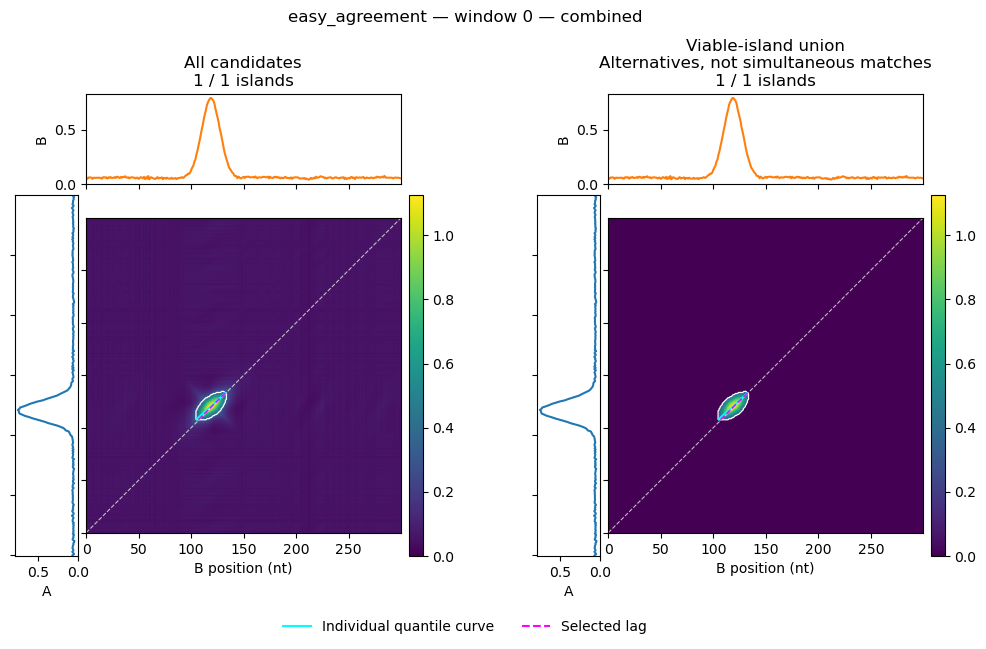

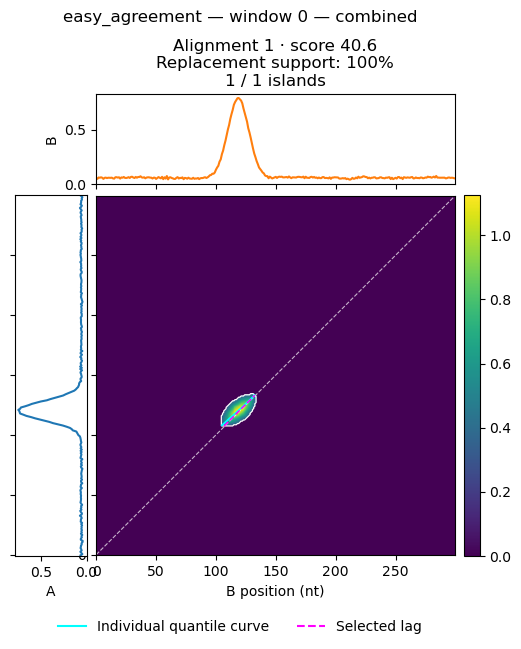

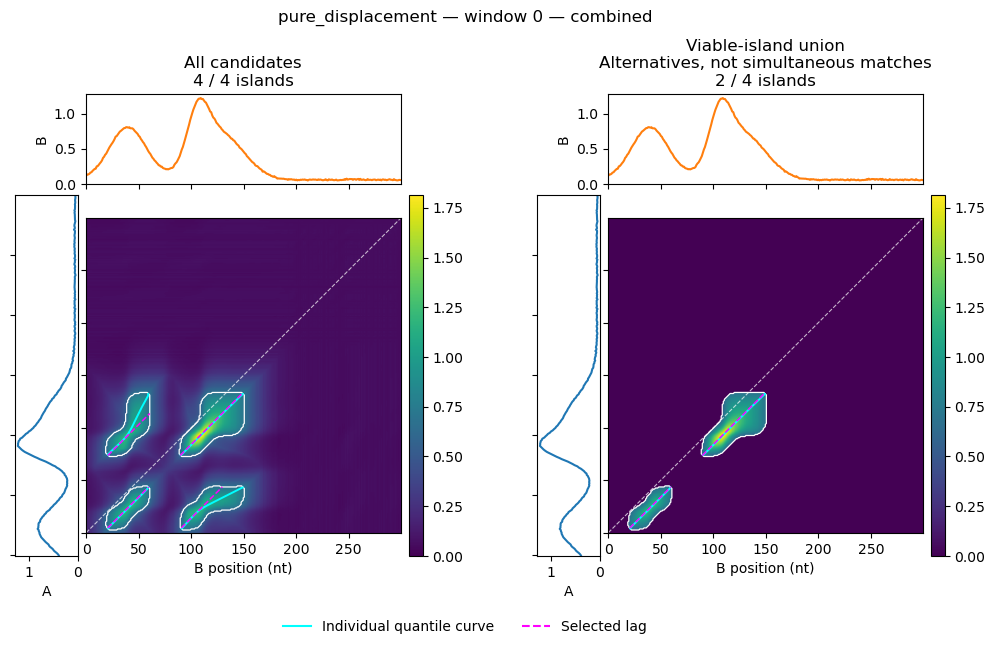

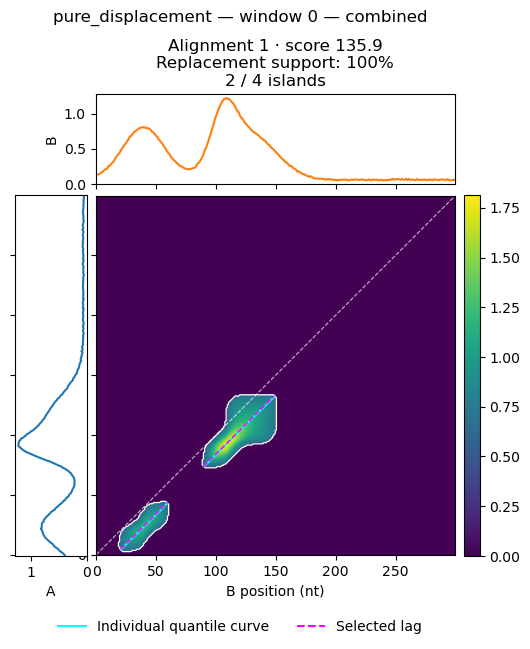

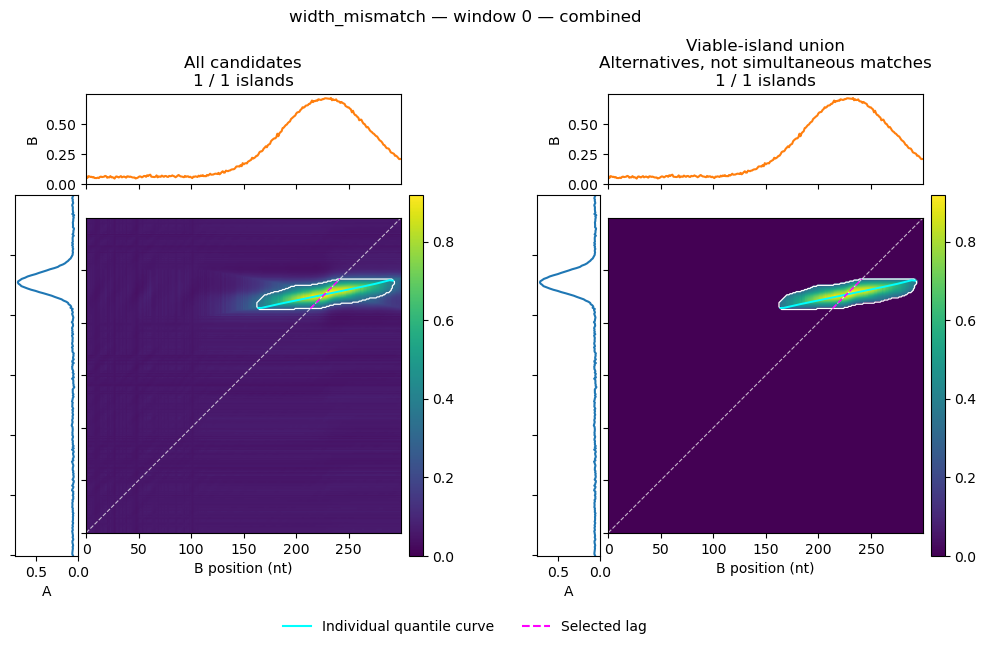

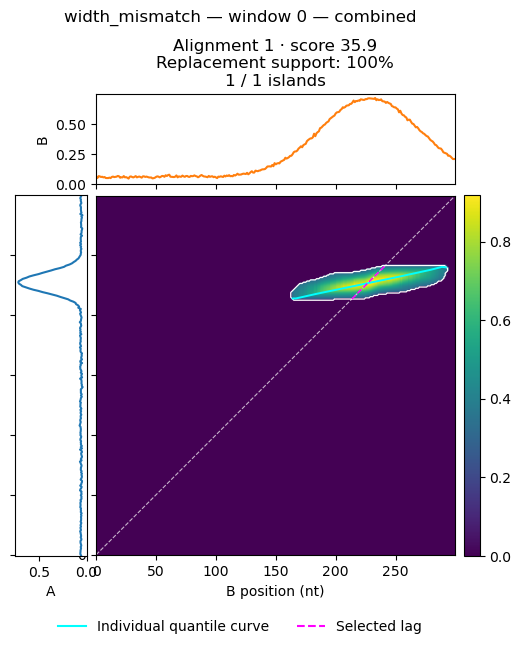

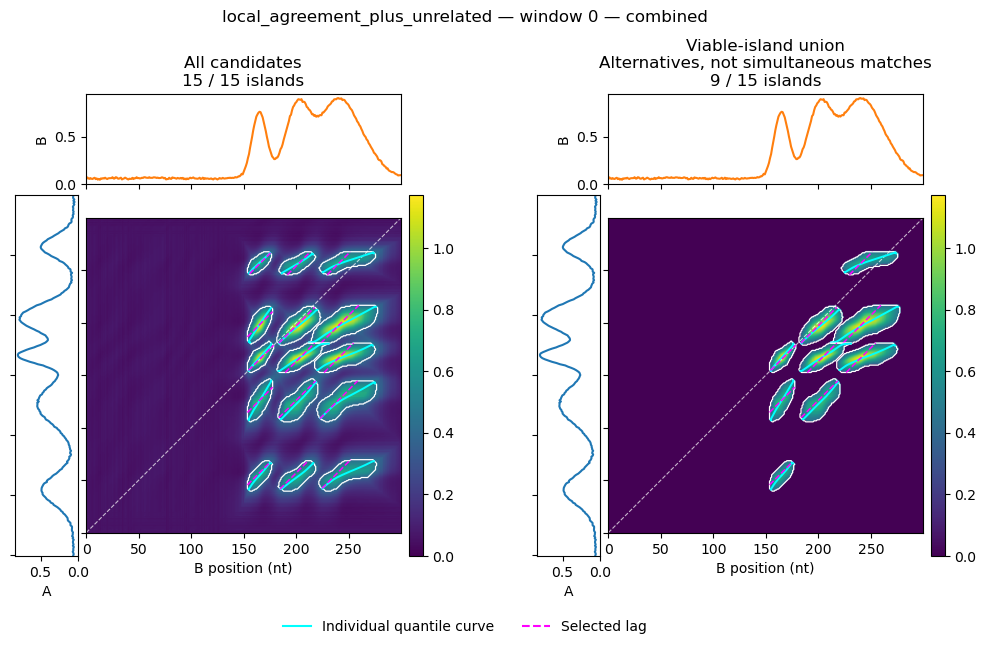

Showing 3 / 4 retained alignments for local_agreement_plus_unrelated; use plot_alignment_alternatives(..., max_panels=None) to show all.


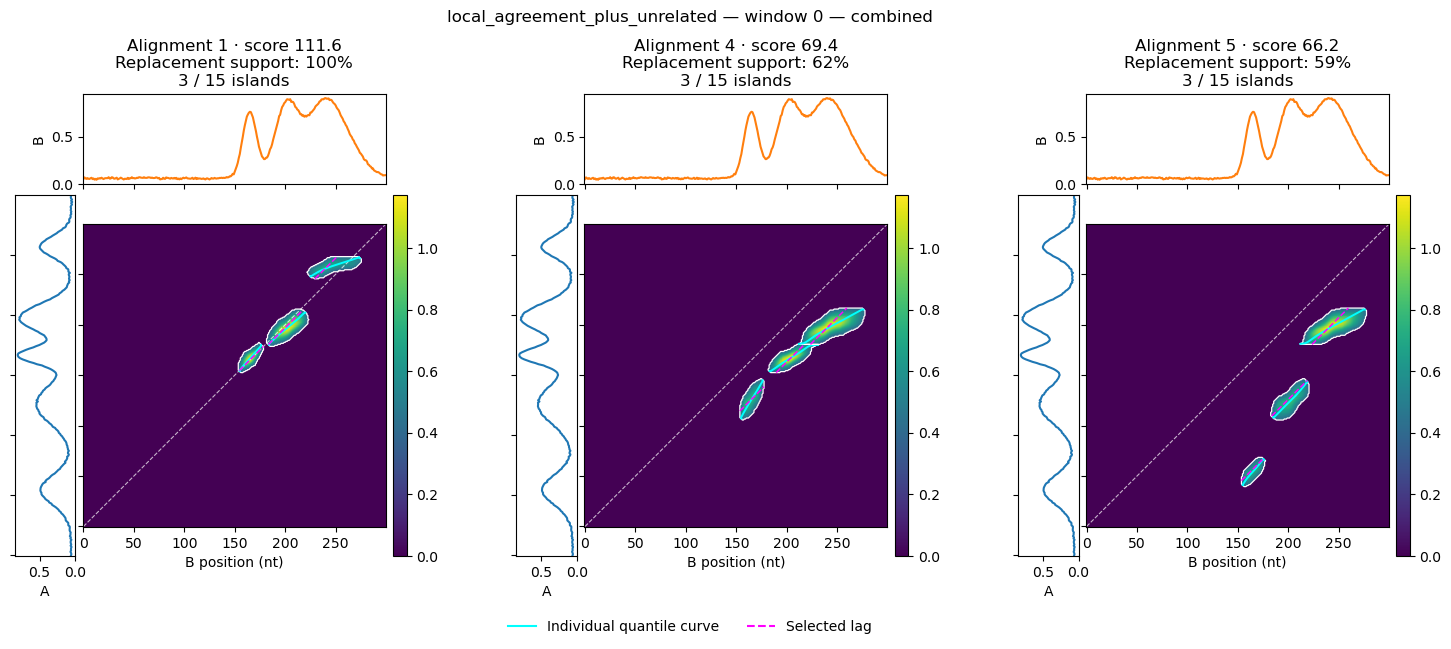

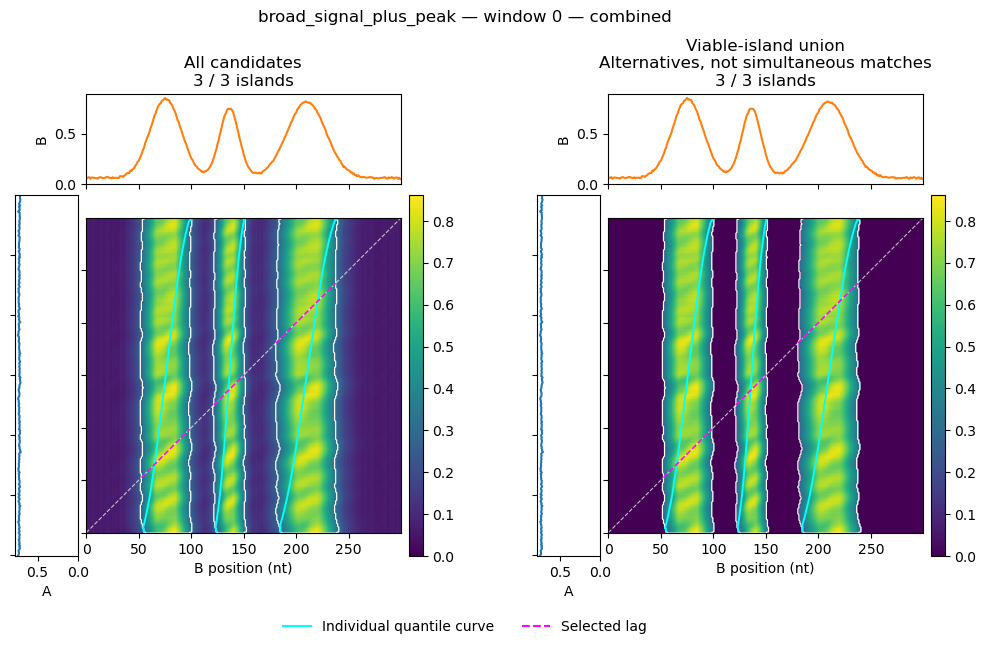

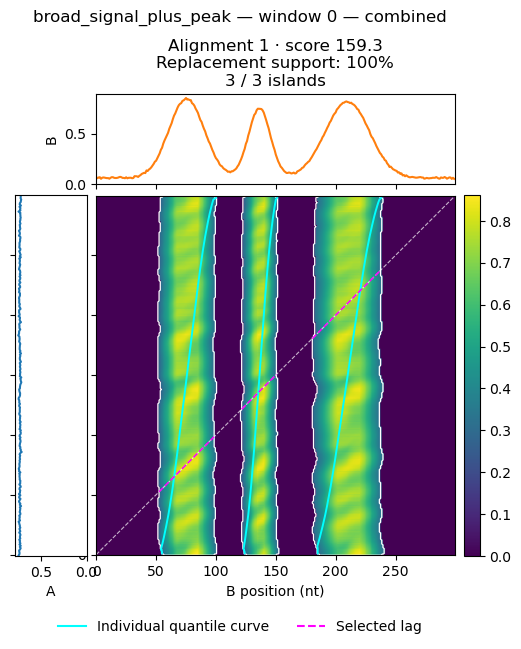

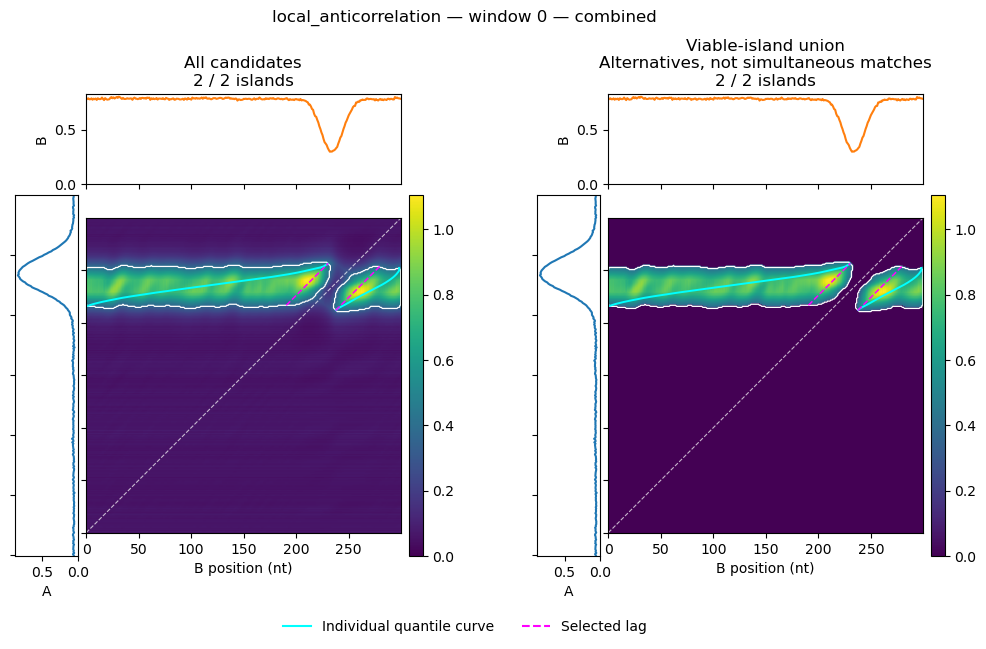

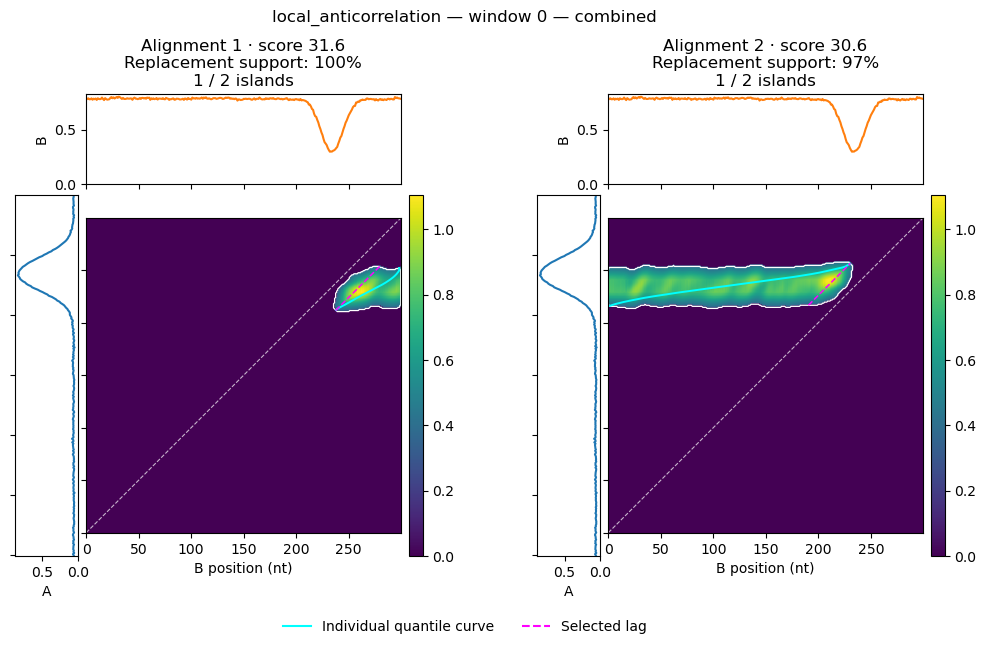

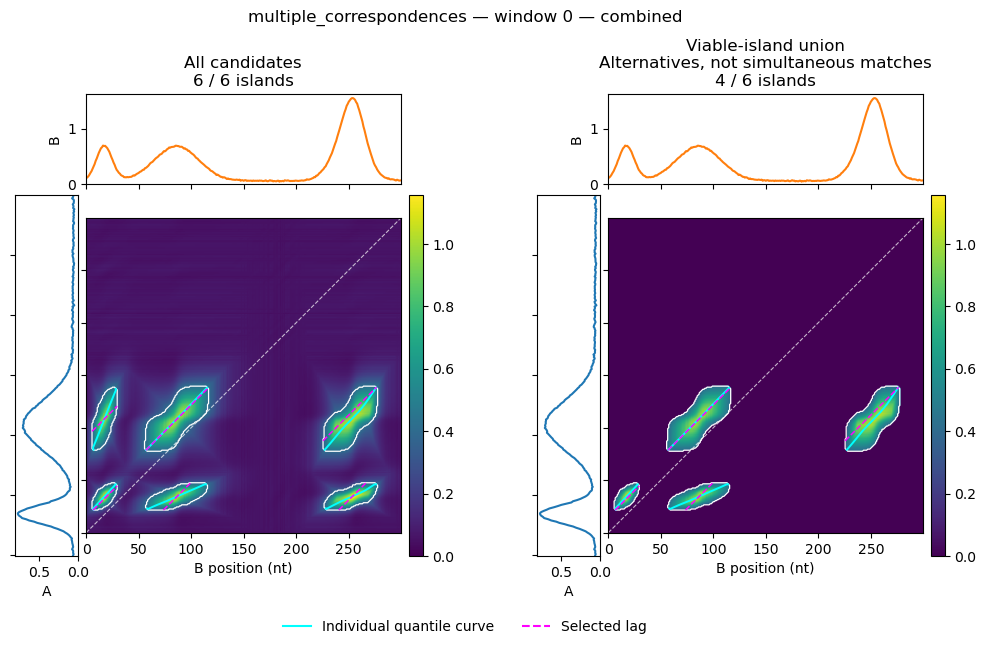

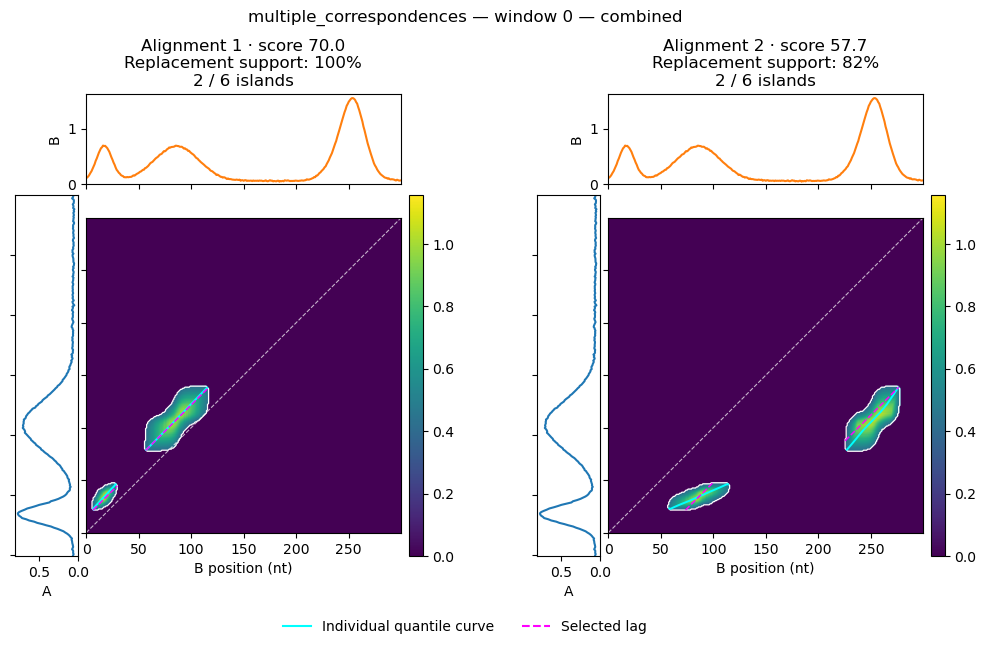

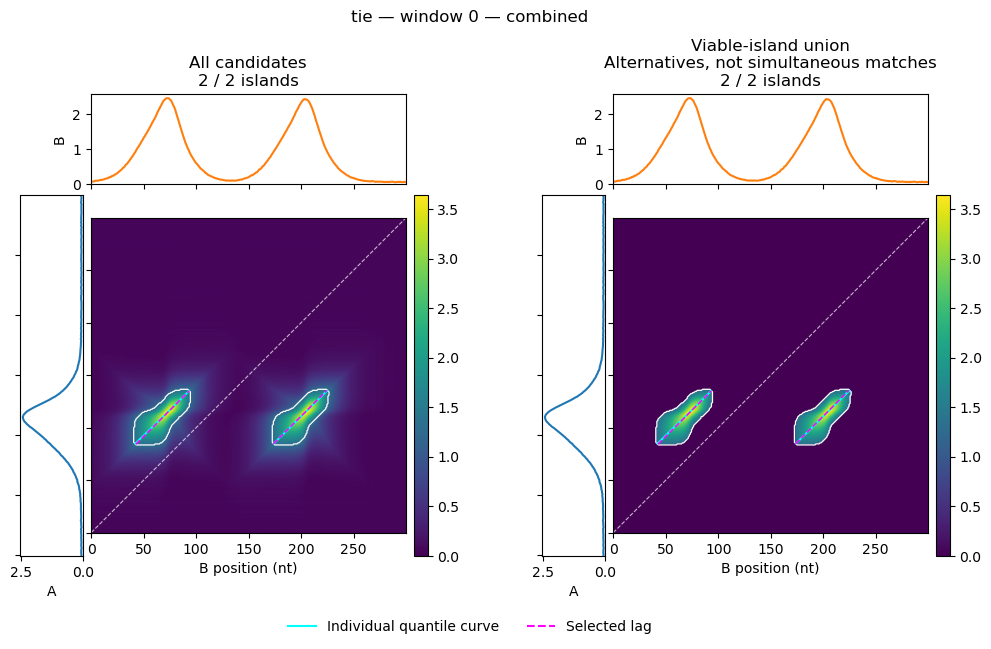

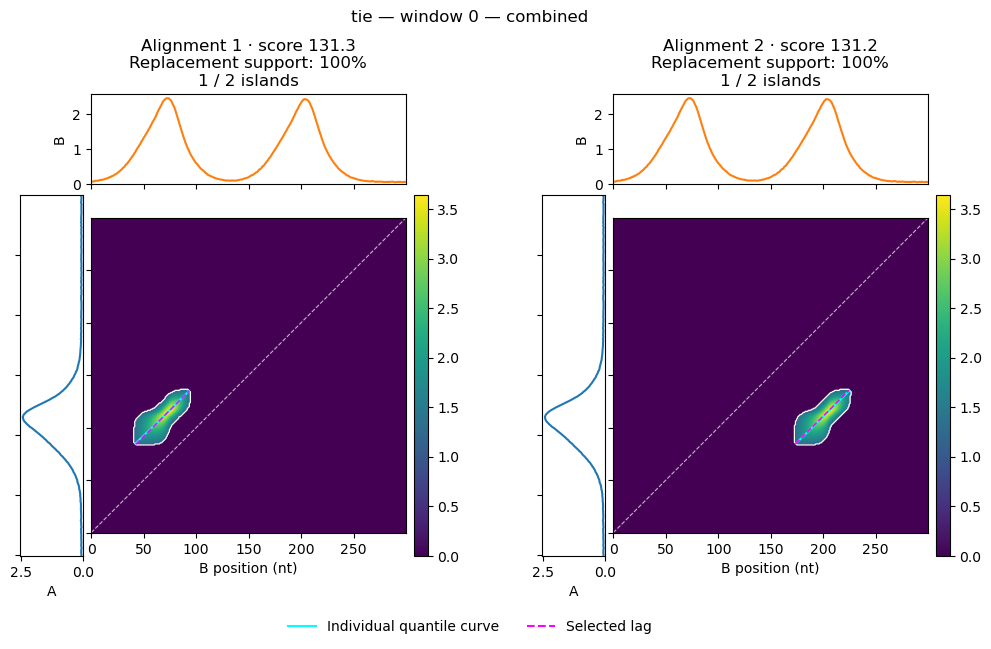

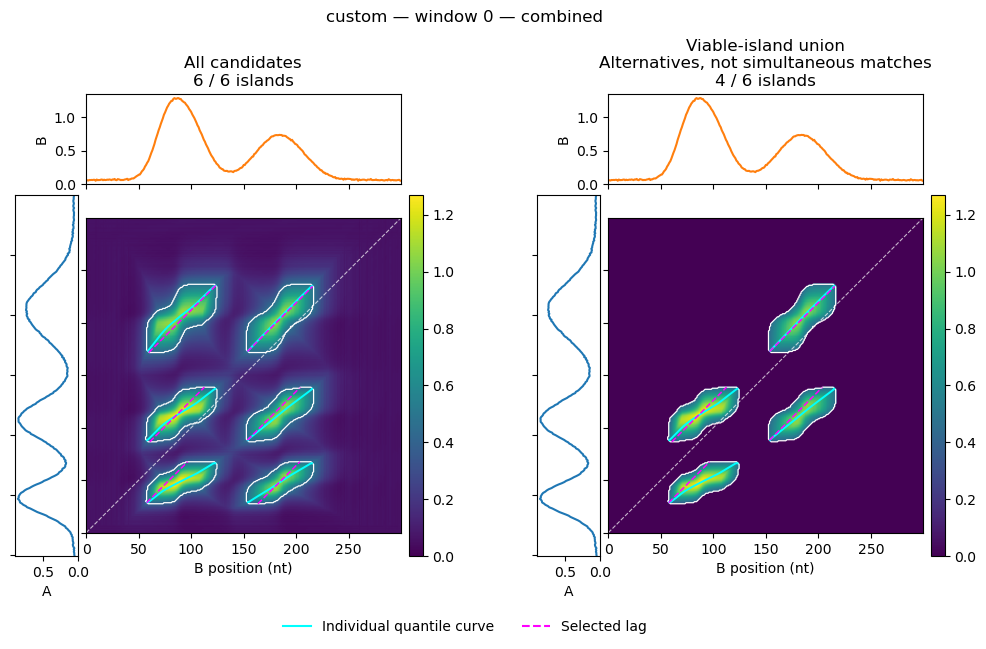

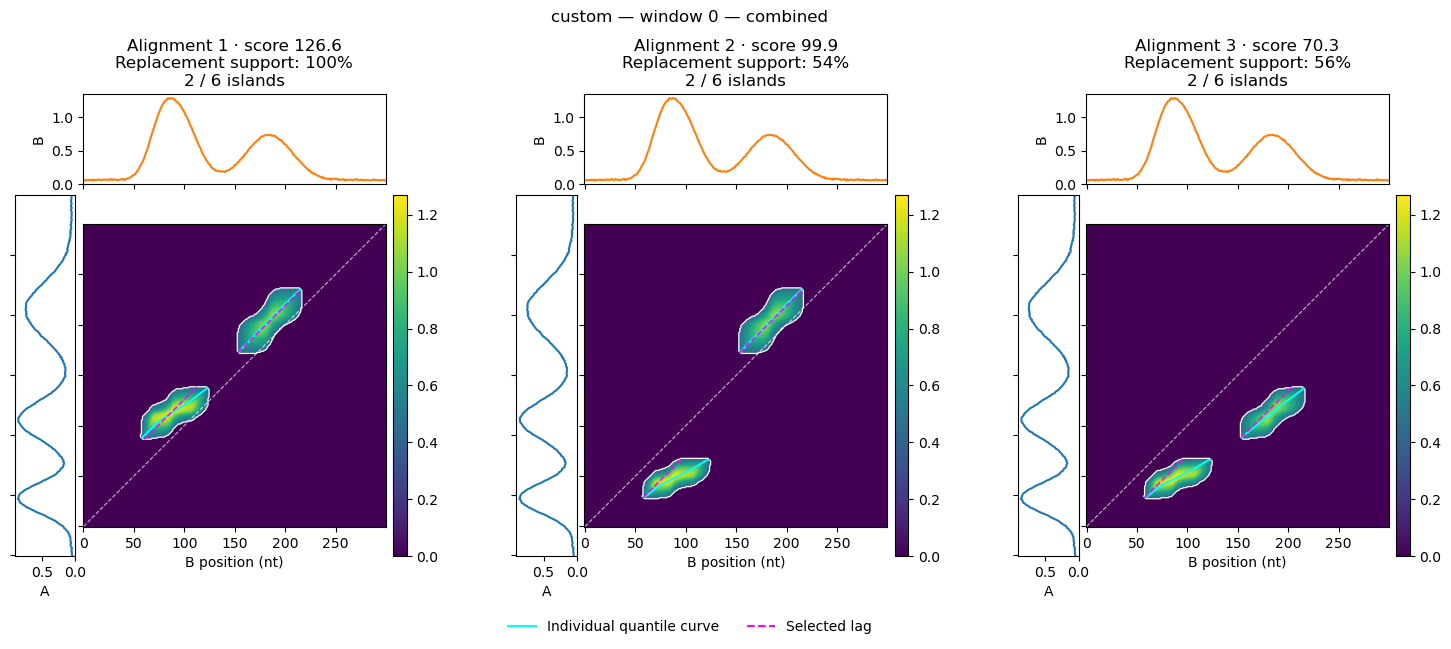

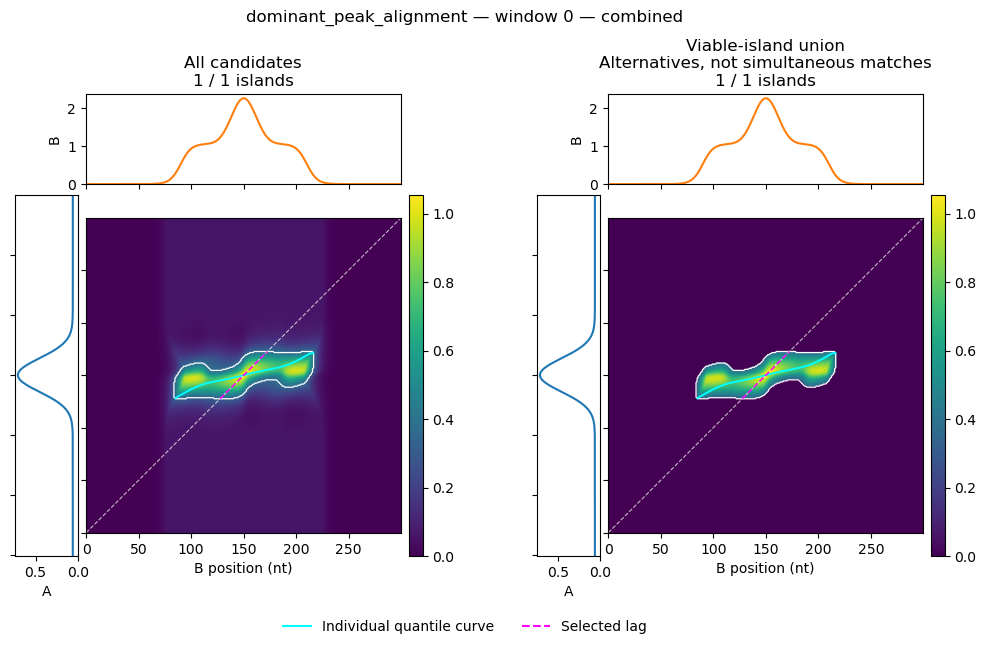

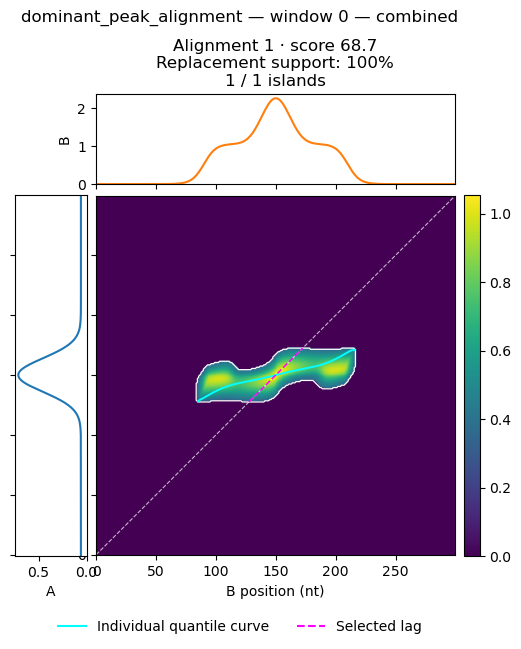

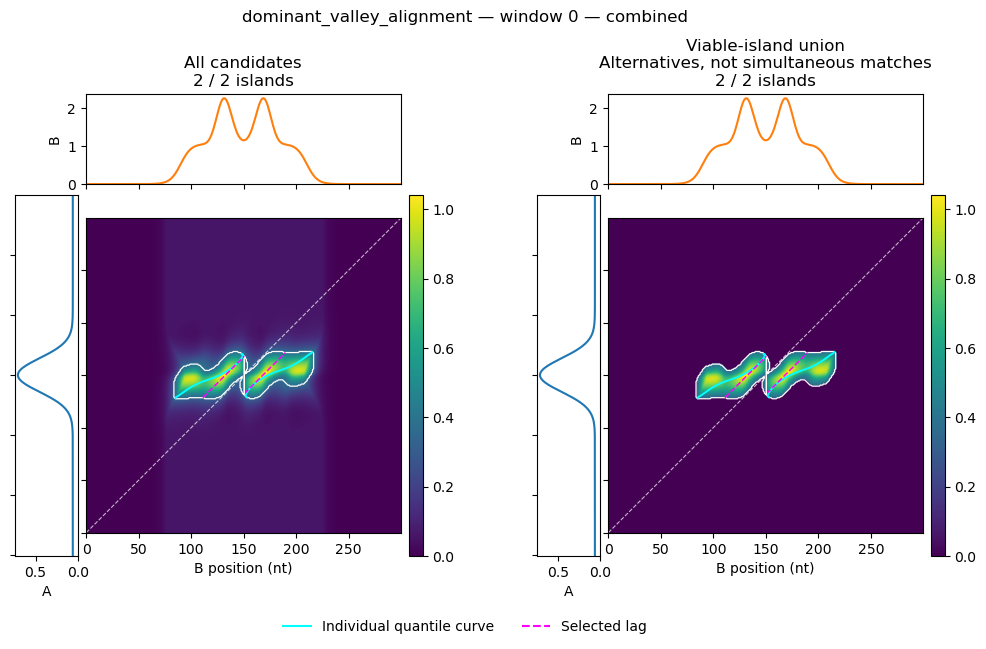

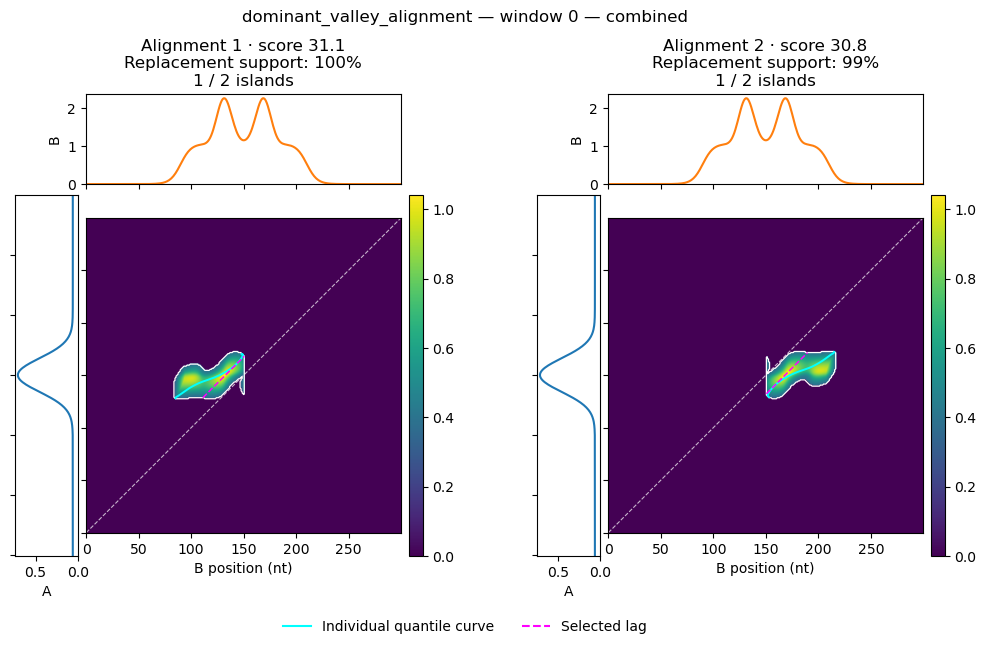

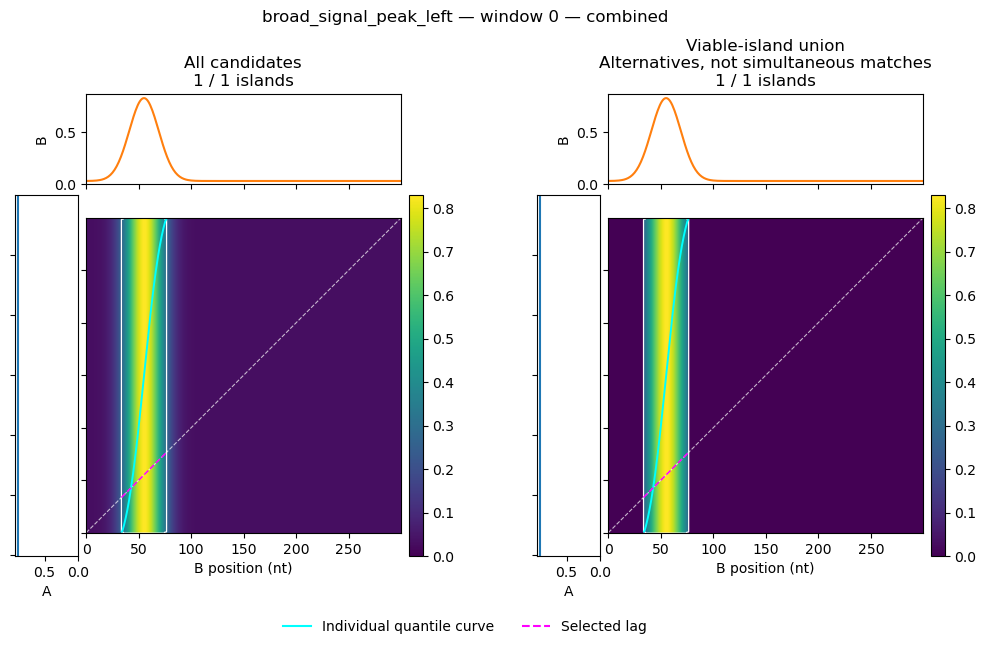

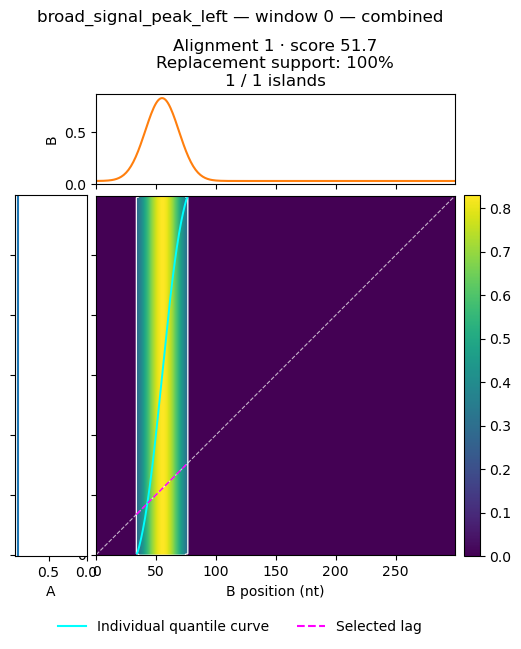

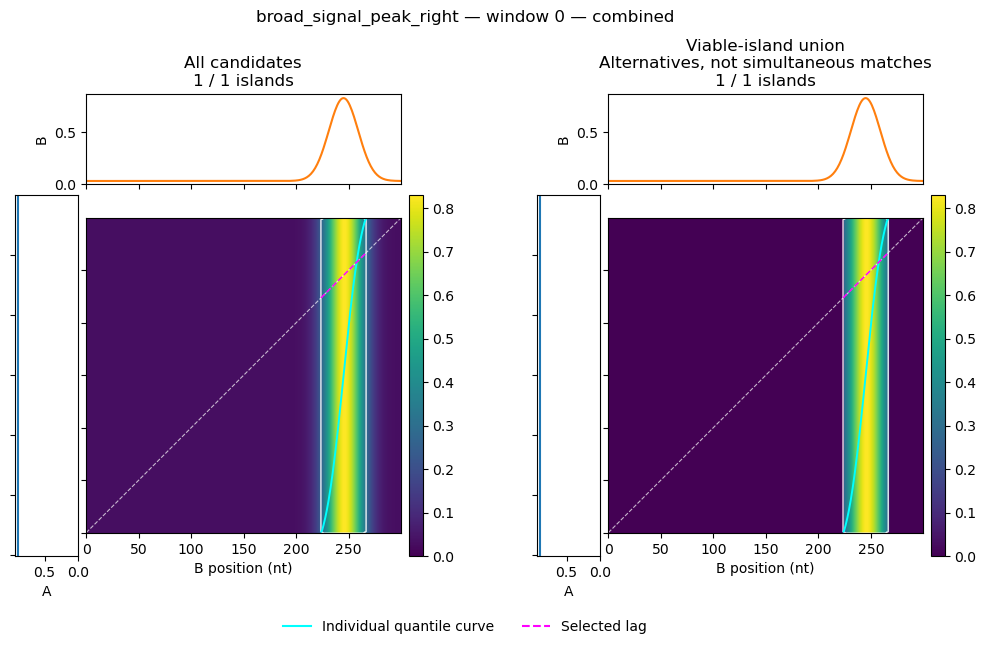

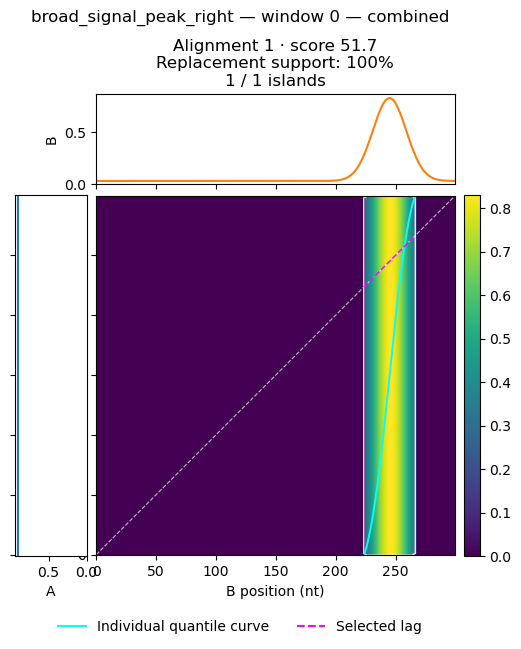

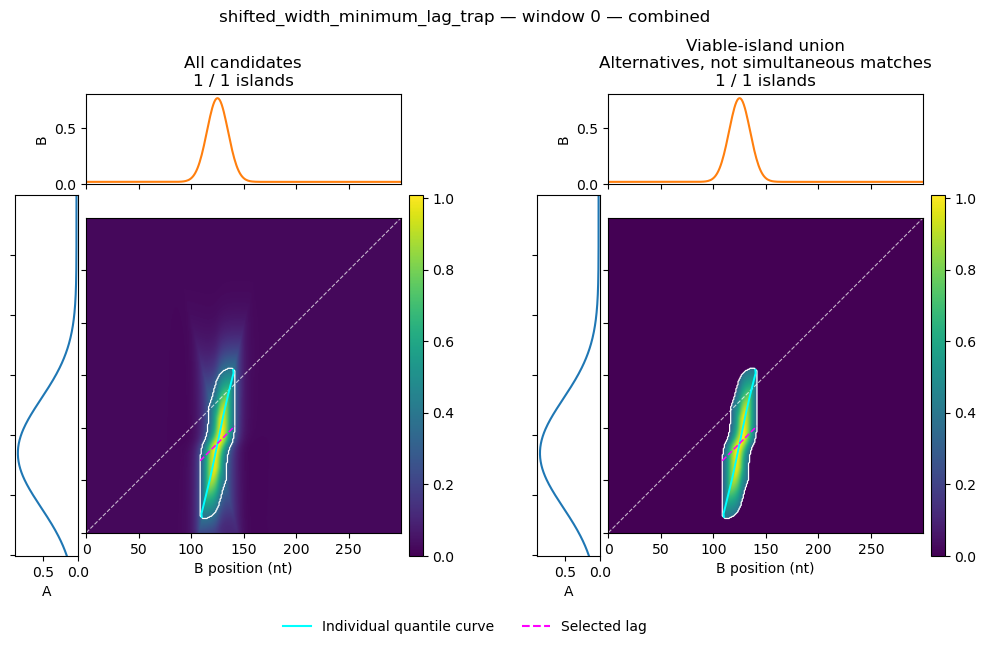

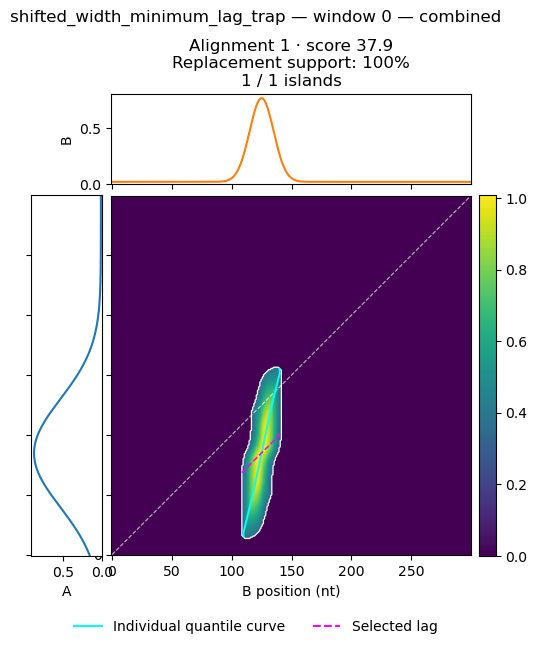

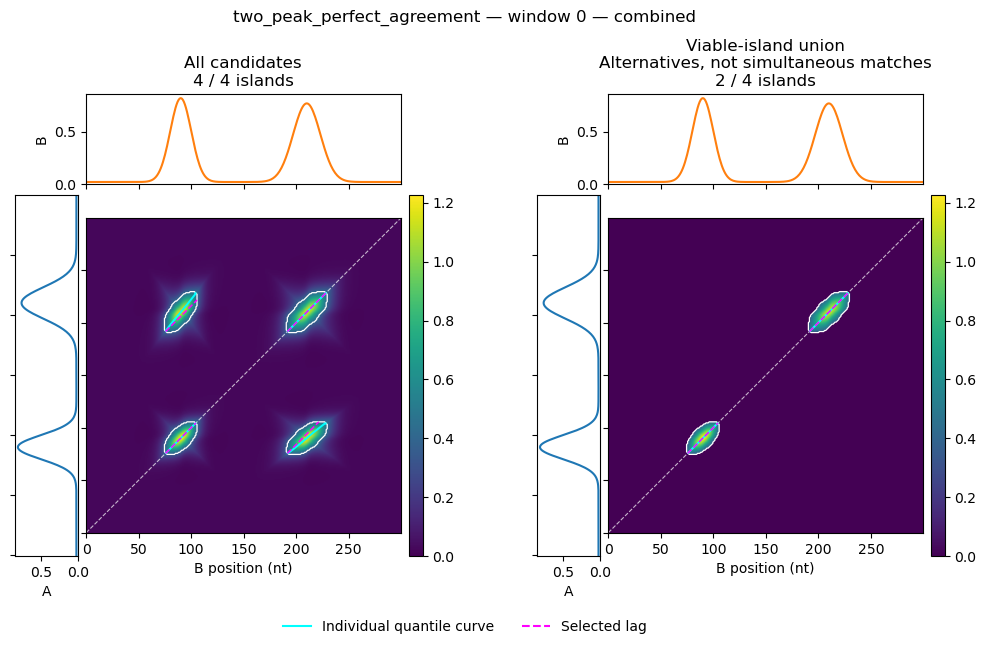

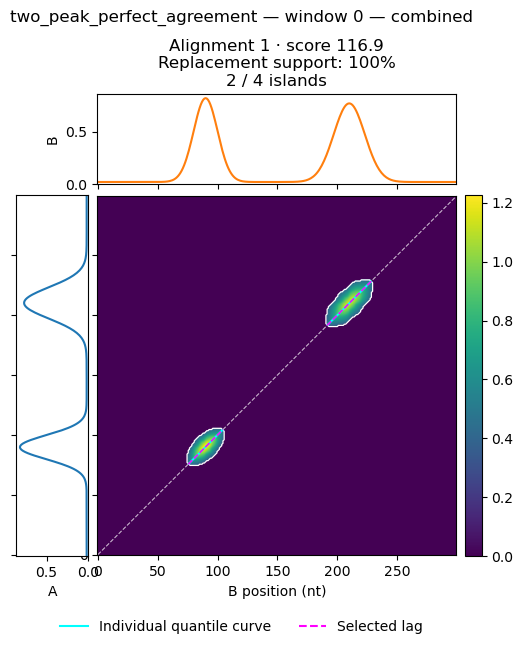

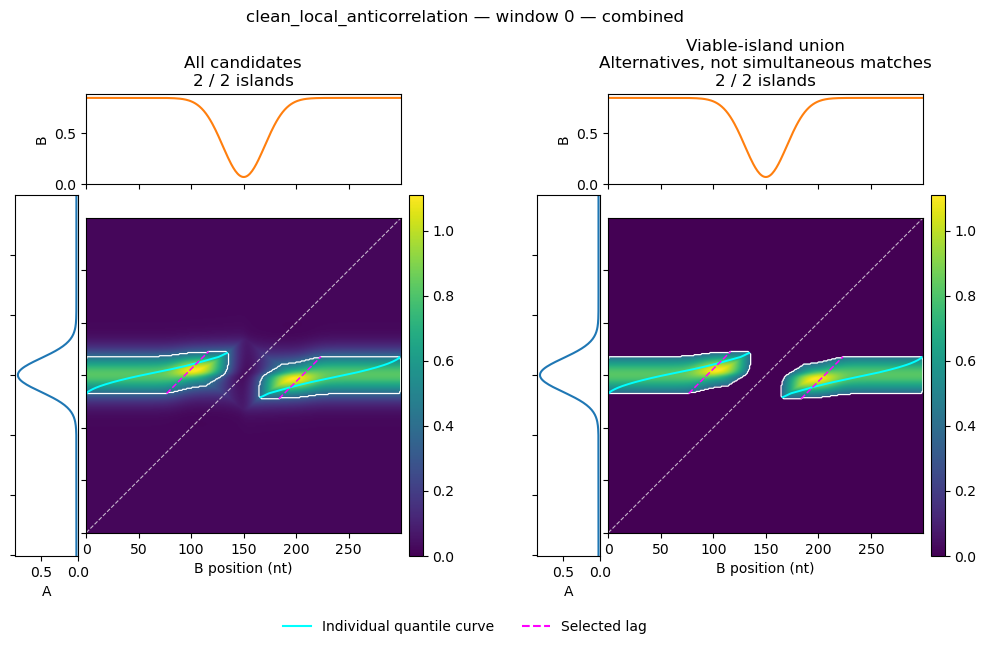

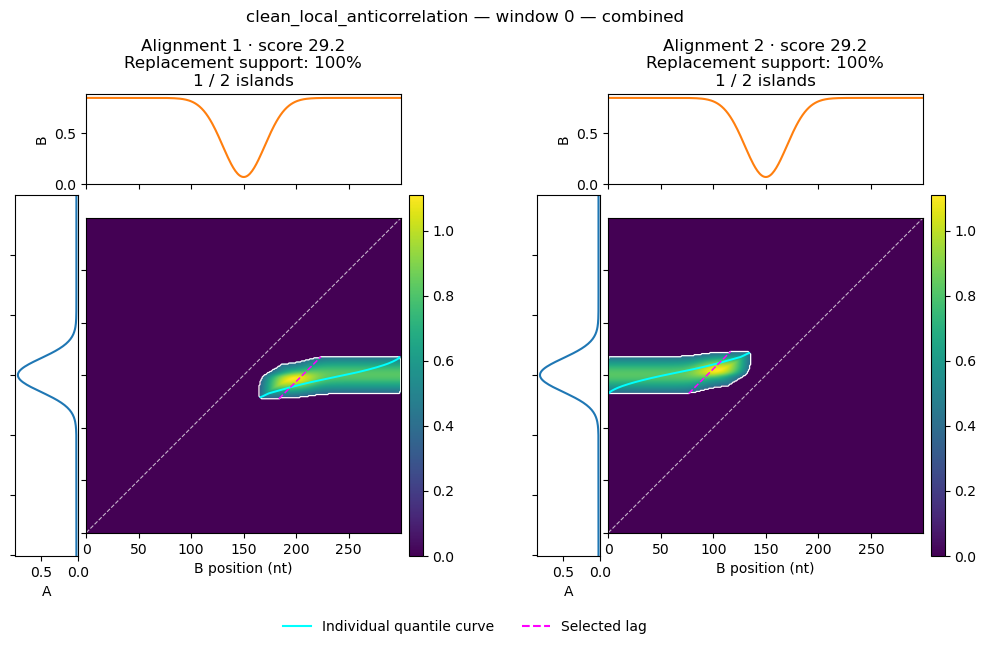

In [126]:
if SHOW_SELECTION_COMPARISONS:
    plot_ordered_results()

## Displacement controls

The off-center pillars should retain their minimum lag. In the stress case, A and B peak centers differ by **+40 nt**. The minimum matrix can have a plateau of equally good shifts; the combined matrix may give a more specific best shift.

`best_relative_gain` is a fraction: 0.10 means a 10% improvement over the minimum-displacement baseline. This table describes split candidates; unsplit plots are computed separately when requested.

In [127]:
displacement_comparison

,scenario,matrix,region_id,selected_lag_b_minus_a,selected_diagonal_score,best_relative_gain,displacement_status
159,broad_signal_peak_left,minimum,1,0.0,25.868198,0.000000,minimum_retained
160,broad_signal_peak_left,combined,1,0.0,25.868198,0.000000,minimum_retained
161,broad_signal_peak_right,minimum,1,0.0,25.868198,0.000000,minimum_retained
162,broad_signal_peak_right,combined,1,0.0,25.868198,0.000000,minimum_retained
163,shifted_width_minimum_lag_trap,minimum,1,0.0,15.274708,0.122457,minimum_retained
164,shifted_width_minimum_lag_trap,combined,1,40.0,23.898274,0.704830,improved


In [128]:
if SHOW_DISPLACEMENT_PROFILES:
    plot_displacement_profiles()

## Simulated tracks

In [129]:
if SHOW_TRACK_OVERVIEW:
    plot_simulated_tracks()

## Optional original matrix overview

Enable `SHOW_MATRIX_OVERVIEW` above to show minimum / shape / combined matrices without selection.

In [130]:
if SHOW_MATRIX_OVERVIEW:
    plot_matrix_results()

## All candidate measurements and retention decisions

In [131]:
candidate_metrics[["scenario", "window_idx", "matrix", "region_id", "retained", "in_best_alignment",
                   "selection_status", "selected_lag_b_minus_a", "selection_weight",
                   "best_path_score", "best_path_id", "replacement_fraction", "supporting_hypothesis_ids"]]

,scenario,window_idx,matrix,region_id,retained,in_best_alignment,selection_status,selected_lag_b_minus_a,selection_weight,best_path_score,best_path_id,replacement_fraction,supporting_hypothesis_ids
0,easy_agreement,0,minimum,1,True,True,supported_by_alignment,-1.000000,27.551855,27.551855,1,1.000000,"(1,)"
1,easy_agreement,0,combined,1,True,True,supported_by_alignment,-0.634036,40.592363,40.592363,1,1.000000,"(1,)"
2,easy_agreement,1,minimum,1,True,True,supported_by_alignment,-1.822621,68.655366,120.484687,1,1.000000,"(1,)"
3,easy_agreement,1,minimum,2,False,False,no_competitive_alignment,57.000000,22.630151,22.630151,3,0.187826,()
4,easy_agreement,1,minimum,3,False,False,no_competitive_alignment,-60.000000,27.283326,27.283326,2,0.226446,()
...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,two_peak_perfect_agreement,0,combined,4,True,True,supported_by_alignment,0.000000,63.915207,116.862287,1,1.000000,"(1,)"
173,clean_local_anticorrelation,0,minimum,1,True,True,supported_by_alignment,-37.000000,24.918655,24.918655,1,1.000000,"(1,)"
174,clean_local_anticorrelation,0,minimum,2,True,False,supported_by_alignment,37.000000,24.918655,24.918655,2,1.000000,"(2,)"
175,clean_local_anticorrelation,0,combined,1,True,True,supported_by_alignment,56.000000,29.157059,29.157059,1,1.000000,"(1,)"


<details>
<summary>Calculation notes and inspection examples</summary>

### Displacement scoring

For each candidate mask, sum its matrix signal along every integer B−A diagonal. Pixels outside that mask contribute zero. Scores are **sums**, not means: a short supported diagonal does not win just because it omits weaker positions. The minimum-|lag| point on the visible quantile curve defines the baseline; its score is linearly interpolated between adjacent integer-diagonal scores if its lag is fractional. All supported integer lags are checked, so the search cannot get trapped at a local optimum.

Retain that baseline unless `best_score > baseline_score × (1 + minimum_relative_gain)`. Numerical ties are treated as ties, not improvements. If the baseline score is zero, any positive best score clears this relative threshold. No extra gain floor is added.

The selected score is **candidate-conditioned total support**, not a probability or confidence interval. Window-edge truncation and candidate boundaries can affect it. Equal best scores can leave a broad ambiguity range even though one representative lag is reported. Displacements are calculated independently first, then alignment selection uses their fixed matched intervals.

### Unchanged calculations

The original random scenarios keep their seed and random-number order. Additional deterministic controls compare dominant peak/valley structure, off-center peaks under flat signal, and shifted broad/narrow peaks.

The shape score compares locally centered profiles and slope profiles after shape-only smoothing. Minimum support uses the original tracks. Combined support remains `minimum × (1 + shape_strength × shape)`.

Candidate detection retains the original binary closing, seed restoration, hole filling, and 8-connectivity. Thresholds scale to each matrix's own maximum. Recursive splitting uses the original axis-profile valleys and the visible parameter settings.

Quantile curves use candidate-masked marginals and the existing projection/clipping helpers. Minimum absolute lag is calculated on continuous visible curve segments, without bridging gaps. The minimum and previous median values remain available in `candidate_metrics` for diagnostics, but are not plotted or included in the default result tables. The box-relative perpendicular offset is not window-coordinate displacement.

### Alternative-alignment selection and limitations

The graph compares separate A/B matched intervals, not literal overlap of different two-dimensional island labels. Within a path, intervals must advance without reuse on either axis. Across paths, alternatives may share or conflict freely. The retained union is not a simultaneous alignment or a binding-stoichiometry claim.

Forward and backward passes calculate the best full path containing every positive-weight island. Paths sum existing island weights; ties favor more zero-lag support, then less movement, then deterministic index order. There is no extra count bonus, common-lag requirement, hard zero-lag anchor, or joint lag adjustment.

At most one best witness is reconstructed per island, and identical witnesses are deduplicated. This is not exhaustive enumeration of every possible path, including ties. Every retained island has an accepted witness, recorded in `supporting_hypothesis_ids`.

Retention compares each witness with the single best reference, excluding their shared island IDs. `replacement_fraction` is alternative-only weight divided by reference-only weight. The reference has ratio 1. Shared matches cannot dilute replacement loss, but differing portions are pooled: independently evaluating separate divergence/rejoin blocks remains future work. Best-total-score witnesses are not necessarily the witnesses maximizing this replacement ratio.

A weak anti-correlation partner can still be rejected. Conservative interval bounds, island splitting, and fixed selected lags can also exclude plausible alignments. Zero-lag support is a preference through weights, not an inviolable anchor.

Graph construction and score passes take quadratic work in candidate count; reconstructed witnesses and diagnostic comparisons add overhead. The former exponential retained-set search is removed. Timing remains available in `phase_timings["alignment_selection"]`. Production-scale runtime is not established.

The clean controls are added after the original random draws. The unfiltered simulator and production files are unchanged.

### Inspect one example

`plot_ordered_comparison("pure_displacement", 0)`

`plot_ordered_comparison("clean_local_anticorrelation", 0, matrix_name="minimum")`

`alignment_hypotheses.query("retained")`

`retained_metrics`

### Optional original matrix plots

`plot_matrix_comparison("shifted_width_minimum_lag_trap", 0)`

`plot_matrix_comparison("broad_signal_peak_left", 0, candidate_stage="unsplit")`

`candidate_metrics.query('scenario == "local_anticorrelation"')`

</details>